# 01_general: dataset, preprocessing, JR model background, PCIst

This is the foundational notebook for the EPIC project (Jansen-Rit fits to rat
ERP data, wake vs. anesthesia). It's the only notebook that touches the raw
`.mat` files: it walks through preprocessing step by step, saves the cleaned
datasets to `data/processed/`, and gives background on the Jansen-Rit model
that the MCMC (`02_mcmc.ipynb`) and SBI (`03_sbi.ipynb`) notebooks
build on. And gives info on the PCIst that the SBI (`03_sbi.ipynb`) notebook
build on.

Structure:
1. The empirical dataset (what's in the raw `.mat` files)
2. Preprocessing, step by step (and saving the result for notebooks 2 & 3)
3. Preprocessed data overview (interactive, per subject / per anesthesia)
4. Frequency characterization
5. Jansen-Rit model background + simulations
6. PCIst: what it measures, worked example, calculations

## Setup

Assumes this notebook lives in the project root, next to `src/` and `data/`. If you move it into a `notebooks/`
subfolder, adjust `sys.path.append` and `DATA_ROOT` below accordingly.

In [1]:
import os
import re
import sys
import time

import numpy as np
import scipy as scp
import xarray as xr
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

sys.path.append(os.path.abspath('src'))
import data as dat
import jansen_rit as jrm
import pcist
import plotting

plotting.apply_house_style()

print('JAX backend:', jax.default_backend())

DATA_ROOT = 'data'
PROCESSED_DIR = os.path.join(DATA_ROOT, 'processed')
os.makedirs(PROCESSED_DIR, exist_ok=True)

ANES_TYPES = ['keta', 'prop', 'sevo']

/home/milchris/miniconda3/envs/jax-gpu/lib/python3.10/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


JAX backend: gpu


Now we can check which subjects have data for which anesthesia types (not everyone has all 3).

In [2]:
subject_to_anes = dat.discover_available_conditions(DATA_ROOT, anes_types=ANES_TYPES)
subject_to_anes

{'j07': ['prop', 'sevo'],
 'j09': ['sevo'],
 'j12': ['keta', 'prop', 'sevo'],
 'j13': ['keta', 'prop', 'sevo'],
 'j14': ['keta', 'prop', 'sevo'],
 'j15': ['keta', 'prop'],
 'j18': ['sevo'],
 'j21': ['sevo'],
 'j23': ['keta', 'prop', 'sevo'],
 'j24': ['keta', 'prop'],
 'j25': ['keta', 'prop', 'sevo'],
 'j26': ['keta', 'prop', 'sevo']}

## 1. The empirical dataset

The used emperical dataset is Rat EEG recorded under an [EBRAINS
dataset](https://search.kg.ebrains.eu/instances/9400031b-dc13-4444-b161-c574d184fdca):
an electrical stimulus is delivered at *t = 0*, and the evoked response is
recorded on 16 electrodes, both while the rat is awake and under one of three
anesthetics (ketamine, propofol, sevoflurane). Each rat only went through some
subset of the three anesthesia sessions, so the amount of data per subject
varies (see `subject_to_anes` above).

Each raw `.mat` file has:

| Key | Shape | Meaning |
|---|---|---|
| `eeg` | (samples, channels, trials) = (5001, 16, 90) | the actual recording, in mV |
| `eeg_diff` | (samples, trials) | spontaneous activity, not used here |
| `time` | (5001,) | time axis in **seconds**, -5s to +5s around the stimulus |
| `fs` | scalar | sampling rate after downsampling, 500 Hz |
| `badCh` | vector | indices of manually rejected channels (0 = none, for our files) |

Let's load one raw recording and look at it directly, before any preprocessing.

In [3]:
example_subject = 'j12'
example_anes = 'keta'

wake_raw, anes_raw = dat.load_raw_pair(DATA_ROOT, example_subject, example_anes)

print(f"wake eeg shape:  {wake_raw['eeg'].shape}, fs = {wake_raw['fs']} Hz")
print(f"{example_anes} eeg shape: {anes_raw['eeg'].shape}")
print(f"time range: {wake_raw['time_ms'][0]:.0f} ms to {wake_raw['time_ms'][-1]:.0f} ms")
print(f"bad channels (wake): {wake_raw['bad_channels']}")

wake eeg shape:  (5001, 16, 90), fs = 500.0 Hz
keta eeg shape: (5001, 16, 90)
time range: -5000 ms to 5000 ms
bad channels (wake): [0]


Now we can plot the emperical data for a single wake trial, for all 16 channels with a vertical offset (such that they don't overlap).

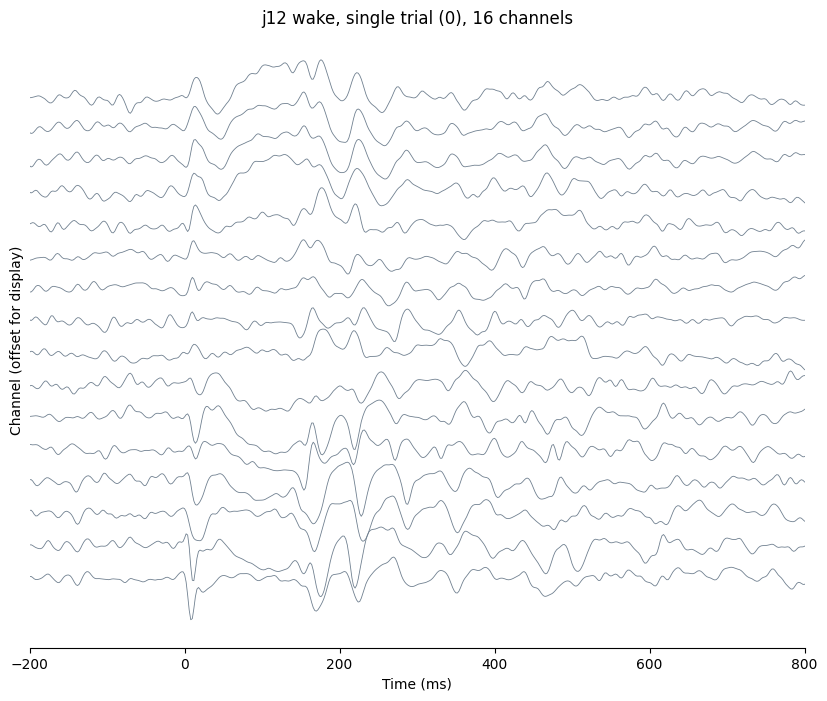

In [4]:
trial = 0
offset = 150

fig, ax = plt.subplots(figsize=(10, 8))
for ch in range(wake_raw['eeg'].shape[1]):
    ax.plot(wake_raw['time_ms'], wake_raw['eeg'][:, ch, trial] + ch * offset, lw=0.6, color=plotting.ANES_COLORS['wake'])
ax.set_xlim(-200, 800)
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Channel (offset for display)')
ax.set_title(f'{example_subject} wake, single trial ({trial}), 16 channels')
ax.set_yticks([])
plotting.modify_axis_spines(ax, which=['x'], xlim=(-200, 800))
plt.show()

Single trials are noisy: there's a clear disturbance around *t = 0* but it's
hard to say much more. Averaging over all 90 trials cleans this up a lot,
which is exactly why the modeling pipeline often works on trial-averaged data rather than single sweeps.

Now we can compare the trial average data for wake versus under ketamine.

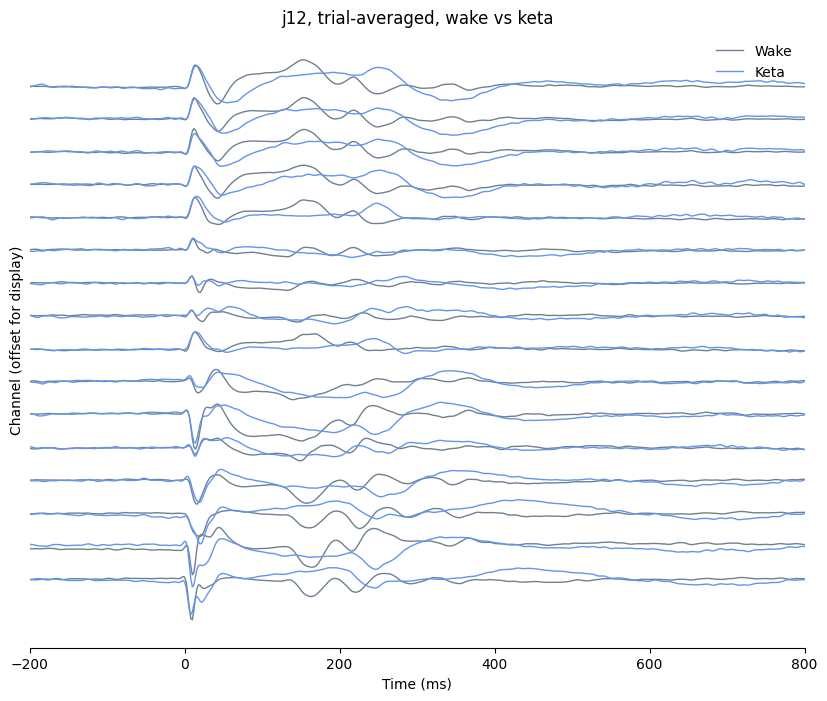

In [5]:
wake_avg = wake_raw['eeg'].mean(axis=2)
anes_avg = anes_raw['eeg'].mean(axis=2)

fig, ax = plt.subplots(figsize=(10, 8))
for ch in range(wake_avg.shape[1]):
    ax.plot(wake_raw['time_ms'], wake_avg[:, ch] + ch * offset, lw=1, color=plotting.ANES_COLORS['wake'], label='Wake' if ch == 0 else None)
    ax.plot(anes_raw['time_ms'], anes_avg[:, ch] + ch * offset, lw=1, color=plotting.ANES_COLORS[example_anes], label=example_anes.capitalize() if ch == 0 else None)
ax.set_xlim(-200, 800)
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Channel (offset for display)')
ax.set_title(f'{example_subject}, trial-averaged, wake vs {example_anes}')
ax.set_yticks([])
ax.legend(frameon=False, loc='upper right')
plotting.modify_axis_spines(ax, which=['x'], xlim=(-200, 800))
plt.show()

There is a visiualdistinction between the two: wake has for most channels a quicker second peak than the keta data. This will also be seen later on. But it is really difficult to get more info out of this visually. That is the goal of this EPIC project.

## 2. Preprocessing, step by step

`src/data.py` has functions that do the full preprocessing in one call
(`preprocess_trial_averaged`, `preprocess_trial_resolved`), but here we will not treat
them as a black box. The steps are:

1. Load the raw `.mat` files and crop to a time window around the stimulus
2. (trial-resolved only) randomly select a handful of trials instead of using all 90
3. Normalize amplitude (scale by the joint wake/anesthesia max, so relative amplitude between conditions is preserved)
4. Smooth: cubic-interpolate onto a finer time grid

Then we run this for real (all subjects, all anesthesia types) and save the
result, so notebooks 2 and 3 never have to touch the raw `.mat` files again.

### Step 1: load raw data and pick a time window

The interesting part of the response is roughly -100 ms to +500 ms around the
stimulus. `tbeg`/`tend` are *sample indices* into the 5001-sample recording
(not times). Index 2450 is the first sample within our window, 2750 the last.

In [6]:
tbeg, tend = 2450, 2750  # sample indices, ~ -100 ms to +500 ms

sample_mat = scp.io.loadmat(dat.list_subject_files(os.path.join(DATA_ROOT, f'PCI-like_{example_anes}1'))[0][example_subject]['wake'])
full_time_s = sample_mat['time'].squeeze()
tbeg_sec, tend_sec = full_time_s[tbeg], full_time_s[tend]
print(f'window: {tbeg_sec*1000:.0f} ms to {tend_sec*1000:.0f} ms, {tend - tbeg} samples')

eeg_wake_full = sample_mat['eeg']
eeg_wake_cropped = eeg_wake_full[tbeg:tend, :, :]
print('full shape:', eeg_wake_full.shape, '-> cropped shape:', eeg_wake_cropped.shape)

window: -100 ms to 500 ms, 300 samples
full shape: (5001, 16, 90) -> cropped shape: (300, 16, 90)


### Step 2: normalize amplitude

We scale both conditions by the *same* factor (the joint max across wake and anesthesia for this subject), so we're not changing the relative amplitude
between the two conditions, just bringing the overall scale into a convenient range (`amp_scaler`, default 6) for the model fits later.

So, amplitude is normalized per subject per anesthesia session (joint wake and anesthesia max within that pair) rather than pooled across sessions or subjects, since electrode contact and gain could differ between separately recorded sessions, so a shared reference point across them is not guaranteed to mean anything. This keeps PCIst and the HF/LF ratio reliable, since both are close to scale invariant, but it means raw amplitudes and fitted MCMC parameters are not directly comparable across different anesthesia conditions or subjects (only between conditions: wake vs. anasthesia).

In this example we use the trial-averaged data, later on we will also look at trial resolved data.

In [7]:
amp_scaler = 6

anes_mat = scp.io.loadmat(dat.list_subject_files(os.path.join(DATA_ROOT, f'PCI-like_{example_anes}1'))[0][example_subject][example_anes])
eeg_anes_cropped = anes_mat['eeg'][tbeg:tend, :, :]

erp_wake_mean = eeg_wake_cropped.mean(-1)   # average over trials -> (time, channel)
erp_anes_mean = eeg_anes_cropped.mean(-1)

erp_max = np.max(np.abs([erp_wake_mean, erp_anes_mean]))
erp_wake_norm = erp_wake_mean / erp_max * amp_scaler
erp_anes_norm = erp_anes_mean / erp_max * amp_scaler

print(f'joint max before scaling: {erp_max:.3f} mV')
print(f'wake range after scaling: [{erp_wake_norm.min():.2f}, {erp_wake_norm.max():.2f}]')

joint max before scaling: 182.835 mV
wake range after scaling: [-5.99, 3.87]


### Step 3: smooth / interpolate

`data.smooth_erp` cubic-interpolates the signal onto a finer time grid
(`freq_scale=2` doubles the sample count). By default it does *not* apply a
low-pass filter first (`apply_lowpass=False`), it's just upsampling, not
denoising. This gives smoother-looking curves for plotting and a finer grid
for the model fits, without throwing away frequency content.

attrs: {'tmin': -0.09999999999999964, 'tmax': 0.5, 'sfreq': 1000}
before smoothing: (300, 16) -> after: (599, 16)


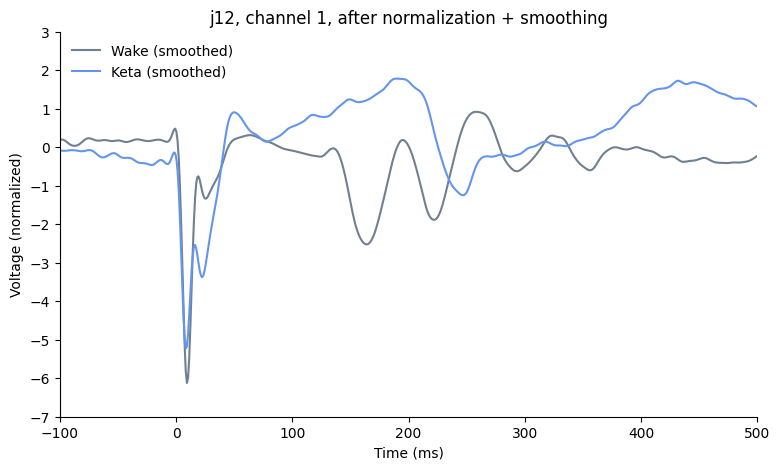

In [8]:
erp_wake_smooth, attrs = dat.smooth_erp(erp_wake_norm, tbeg_sec, tend_sec, sfreq=500, axis=0)
erp_anes_smooth, _ = dat.smooth_erp(erp_anes_norm, tbeg_sec, tend_sec, sfreq=500, axis=0)

print('attrs:', attrs)
print('before smoothing:', erp_wake_norm.shape, '-> after:', erp_wake_smooth.shape)

smooth_time_ms = 1000 * np.linspace(attrs['tmin'], attrs['tmax'], erp_wake_smooth.shape[0])

fig, ax = plt.subplots(figsize=(9, 5))
ch = 0
ax.plot(smooth_time_ms, erp_wake_smooth[:, ch], color=plotting.ANES_COLORS['wake'], lw=1.5, label='Wake (smoothed)')
ax.plot(smooth_time_ms, erp_anes_smooth[:, ch], color=plotting.ANES_COLORS[example_anes], lw=1.5, label=f'{example_anes.capitalize()} (smoothed)')
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Voltage (normalized)')
ax.set_title(f'{example_subject}, channel {ch+1}, after normalization + smoothing')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(smooth_time_ms.min()), float(smooth_time_ms.max())))
ax.legend(frameon=False)
plt.show()

### Now for real: preprocess everything and save it

That was the full pipeline for the trial-averagad data of one subject and one channel. `data.py`'s
`preprocess_trial_averaged` and `preprocess_trial_resolved` do exactly the
same steps (loop over every subject in a folder, same normalize + smooth
logic) and save the result. We run this once per anesthesia type and save to
`data/processed/`. Notebooks 2 and 3 load these files directly and never
touch the raw `.mat`s.

`n_trials` controls how many random trials are kept for the trial-resolved
dataset (kept small, the SBI notebook uses this for per-trial pipelines, and
PCIst on many trials adds up computationally).

The cell below always writes to the same filenames (`{anes}_all_erps.nc`,
`{anes}_single_trials.nc`), so re-running it just overwrites the previous
version in place. No timestamped copies pile up in `data/processed/`, the
folder always reflects whatever the last run produced.

In [9]:
n_trials = 5
random_state = 0

erp_datasets = {}
trial_datasets = {}

for anes in ANES_TYPES:
    folder = os.path.join(DATA_ROOT, f'PCI-like_{anes}1') + os.sep
    print(f'preprocessing {anes}...')

    erp_datasets[anes] = dat.preprocess_trial_averaged(
        folder, cond_anes=anes, data_dir=PROCESSED_DIR + os.sep, tbeg=tbeg, tend=tend, save_output=True)

    trial_datasets[anes] = dat.preprocess_trial_resolved(
        folder, cond_anes=anes, data_dir=PROCESSED_DIR + os.sep, tbeg=tbeg, tend=tend,
        n_trials=n_trials, save_output=True, random_state=random_state)

print('done. saved to', PROCESSED_DIR)
sorted(os.listdir(PROCESSED_DIR))

preprocessing keta...
preprocessing prop...
preprocessing sevo...
done. saved to data/processed


['keta_all_erps.nc',
 'keta_pci_trials.nc',
 'keta_pcist.nc',
 'keta_single_trials.nc',
 'keta_sliding_pci.nc',
 'keta_sliding_pci_avg.nc',
 'prop_all_erps.nc',
 'prop_pci_trials.nc',
 'prop_pcist.nc',
 'prop_single_trials.nc',
 'prop_sliding_pci.nc',
 'prop_sliding_pci_avg.nc',
 'sevo_all_erps.nc',
 'sevo_pci_trials.nc',
 'sevo_pcist.nc',
 'sevo_single_trials.nc',
 'sevo_sliding_pci.nc',
 'sevo_sliding_pci_avg.nc']

From here on we reload from disk rather than reusing the variables above, just
to make sure what we're looking at is really what got saved (and what
notebooks 2/3 will load).

In [10]:
erp_datasets = {anes: xr.load_dataarray(os.path.join(PROCESSED_DIR, f'{anes}_all_erps.nc')) for anes in ANES_TYPES}
trial_datasets = {anes: xr.load_dataarray(os.path.join(PROCESSED_DIR, f'{anes}_single_trials.nc')) for anes in ANES_TYPES}

## 3. Preprocessed data overview

Now that we have preprocessed the data, we can investigate it a bit further. We start with plotting the EEG data for each subject.

In [11]:
def plot_preprocessed_overview(subject, anes_list):
    fig, axes = plt.subplots(1, len(anes_list), figsize=(5.5 * len(anes_list), 4.5), squeeze=False)
    for ax, anes in zip(axes[0], anes_list):
        da = erp_datasets[anes]
        time_ms = 1000 * da.coords['time'].values
        wake_data = da.sel(subject=subject, condition='wake').dropna('region')
        anes_data = da.sel(subject=subject, condition=anes).dropna('region')

        for r in range(wake_data.shape[-1]):
            ax.plot(time_ms, wake_data[:, r], c=plotting.ANES_COLORS['wake'], alpha=0.6, lw=1)
        for r in range(anes_data.shape[-1]):
            ax.plot(time_ms, anes_data[:, r], c=plotting.ANES_COLORS[anes], alpha=0.6, lw=1)
        ax.plot([], [], c=plotting.ANES_COLORS['wake'], label='Wake')
        ax.plot([], [], c=plotting.ANES_COLORS[anes], label=anes.capitalize())

        ax.set_xlabel('Time (ms)')
        ax.set_ylabel('Voltage (normalized)')
        ax.set_title(f'{subject} — {anes.capitalize()}')
        ax.legend(frameon=False)
        plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(time_ms.min()), float(time_ms.max())), ylim=(-6, 4))
    fig.tight_layout()
    plt.show()

plotting.subject_explorer(plot_preprocessed_overview, subject_to_anes)

Dropdown(description='Subject:', index=2, options=('j07', 'j09', 'j12', 'j13', 'j14', 'j15', 'j18', 'j21', 'j2…

Output()

### Averaged per anesthesia type

Same idea, but instead of one subject's individual channels, this averages
over every subject with that anesthesia type first.

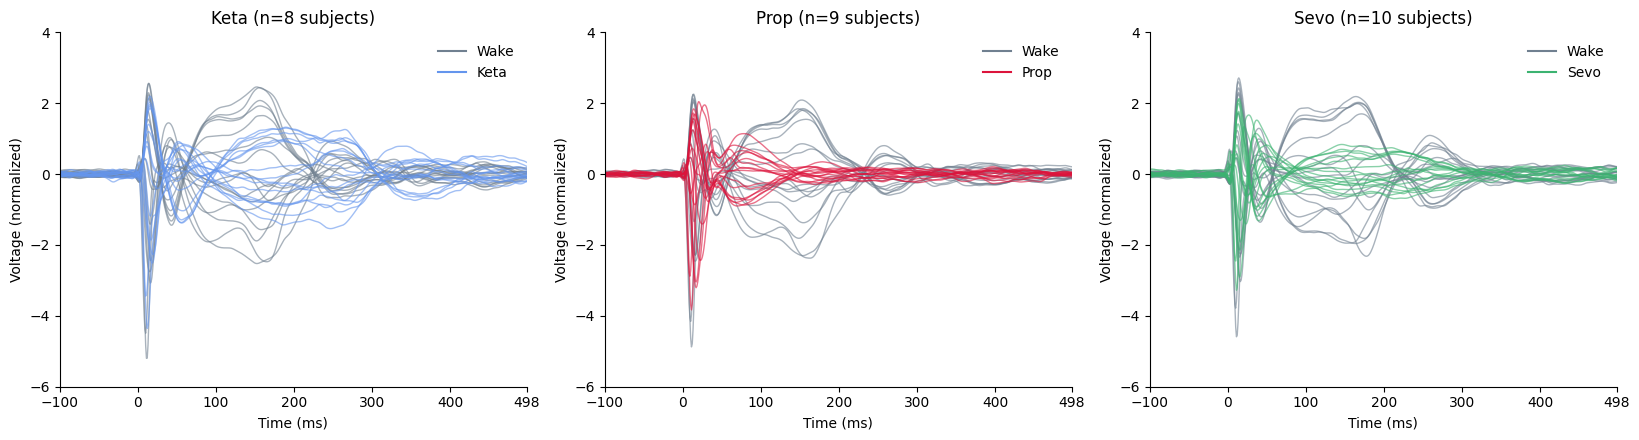

In [12]:
fig, axes = plt.subplots(1, len(ANES_TYPES), figsize=(5.5 * len(ANES_TYPES), 4.5))
for ax, anes in zip(axes, ANES_TYPES):
    da = erp_datasets[anes]
    time_ms = 1000 * da.coords['time'].values
    wake_mean = da.sel(condition='wake').mean('subject', skipna=True)
    anes_mean = da.sel(condition=anes).mean('subject', skipna=True)

    for r in range(wake_mean.shape[-1]):
        ax.plot(time_ms, wake_mean[:, r], c=plotting.ANES_COLORS['wake'], alpha=0.6, lw=1)
    for r in range(anes_mean.shape[-1]):
        ax.plot(time_ms, anes_mean[:, r], c=plotting.ANES_COLORS[anes], alpha=0.6, lw=1)
    ax.plot([], [], c=plotting.ANES_COLORS['wake'], label='Wake')
    ax.plot([], [], c=plotting.ANES_COLORS[anes], label=anes.capitalize())

    n_subj = da.sel(condition=anes).dropna('subject', how='all').sizes['subject']
    ax.set_title(f'{anes.capitalize()} (n={n_subj} subjects)')
    ax.set_xlabel('Time (ms)')
    ax.set_ylabel('Voltage (normalized)')
    ax.legend(frameon=False)
    plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(time_ms.min()), float(time_ms.max())), ylim=(-6, 4))
fig.tight_layout()
plt.show()

### All wake vs. all anesthesia, pooled

A grand-average comparison: every wake recording (one per anesthesia session,
so the same rat can contribute more than once) against every anesthesia
recording, pooled across subjects, sessions and channels. Shaded band is ±1
SEM. This throws away the per-anesthesia distinction, so it's a blunt
instrument, but it's a quick check that "wake" and "anesthesia" look different
at all.

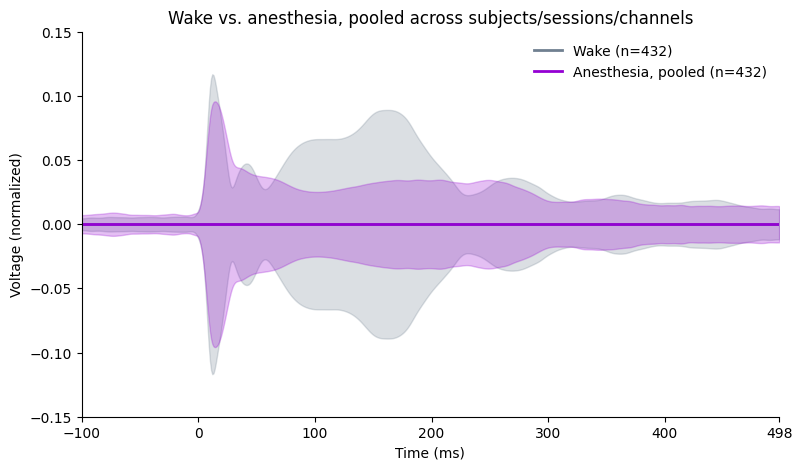

In [13]:
def pool_condition(condition_getter):
    """condition_getter(anes) -> DataArray for that condition; flattens (subject, region) into one axis."""
    pooled = []
    for anes in ANES_TYPES:
        arr = condition_getter(anes).dropna('subject', how='all')
        pooled.append(arr.stack(sample=('subject', 'region')).values)
    return np.concatenate(pooled, axis=-1)  # (time, n_pooled_samples)

wake_pooled = pool_condition(lambda anes: erp_datasets[anes].sel(condition='wake'))

# the anesthesia condition label differs per dataset ('keta'/'prop'/'sevo'), so build it directly:
anes_pooled = np.concatenate([
    erp_datasets[anes].sel(condition=anes).dropna('subject', how='all').stack(sample=('subject', 'region')).values
    for anes in ANES_TYPES
], axis=-1)

time_ms = 1000 * erp_datasets['keta'].coords['time'].values

def mean_sem(arr):
    mean = np.nanmean(arr, axis=-1)
    sem = np.nanstd(arr, axis=-1, ddof=1) / np.sqrt(np.sum(~np.isnan(arr), axis=-1))
    return mean, sem

wake_mean, wake_sem = mean_sem(wake_pooled)
anes_mean, anes_sem = mean_sem(anes_pooled)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(time_ms, wake_mean, c=plotting.ANES_COLORS['wake'], lw=2, label=f'Wake (n={wake_pooled.shape[-1]})')
ax.fill_between(time_ms, wake_mean - wake_sem, wake_mean + wake_sem, color=plotting.ANES_COLORS['wake'], alpha=0.25)
ax.plot(time_ms, anes_mean, c='darkviolet', lw=2, label=f'Anesthesia, pooled (n={anes_pooled.shape[-1]})')
ax.fill_between(time_ms, anes_mean - anes_sem, anes_mean + anes_sem, color='darkviolet', alpha=0.25)
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Voltage (normalized)')
ax.set_title('Wake vs. anesthesia, pooled across subjects/sessions/channels')
ax.legend(frameon=False)
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(time_ms.min()), float(time_ms.max())))
plt.show()

From this we see that in general, the wake and anasthesia emperical differ visually, as the wake data has around 100-200 ms often a bigger absolute value than the anasthesia data.

But visual comparison only gets us so far. Now we have to get more creative...

## 4. Frequency characterization

Now we will study some frequency aspects of the data. Two analyses, each shown at two levels: per-subject (dropdown) and pooled/averaged across subjects.

Important: these run on the **raw, un-preprocessed** recordings (`load_raw_pair`), not the smoothed/normalized data from section 2. We want the actual recorded frequency content here, and normalization/interpolation could subtly change it.

### Fourier spectra

We now take a FFT of the time window straight after the stimulus (0-500 ms), per trial per channel, averaged. The expectation, based on human/rodent EEG literature on anesthetics like propofol and sevoflurane, is that these anesthesia shows relatively more low-frequency (≤4 Hz) power and wake relatively more high-frequency (≥20 Hz) power. But ketamine works through a different mechanism (NMDA receptor block) and is reported to increase high-frequency beta/gamma power instead of suppressing it. 

Now we can try to validate these theoretical theories, but keep in mind this is all a bit handwavy, and just for interest, not super scientific.

(Sources: see e.g. Purdon et al., 2013, PNAS, "Electroencephalogram signatures of loss and recovery of consciousness from propofol", and the review in Frontiers in Systems Neuroscience, 2014, "EEG slow-wave coherence changes in propofol-induced general anesthesia").

We first plot the frequency spectrum per subject:

In [14]:
def power_spectrum(eeg, time_ms, window=(0, 500)):
    """Trial- and channel-averaged power spectrum of eeg (samples, channels, trials) within `window` ms."""
    mask = (time_ms >= window[0]) & (time_ms <= window[1])
    dt_s = np.mean(np.diff(time_ms[mask])) / 1000.0
    freqs = np.fft.rfftfreq(mask.sum(), d=dt_s)
    fft = np.fft.rfft(eeg[mask], axis=0)
    power = np.abs(fft) ** 2          # (freqs, channels, trials)
    return freqs, power.mean(axis=(1, 2))


def plot_fourier_spectra(subject, anes_list):
    fig, ax = plt.subplots(figsize=(9, 5))
    wake_powers = []
    for anes in anes_list:
        wake, anes_rec = dat.load_raw_pair(DATA_ROOT, subject, anes)
        freqs, wake_power = power_spectrum(wake['eeg'], wake['time_ms'])
        _, anes_power = power_spectrum(anes_rec['eeg'], anes_rec['time_ms'])
        wake_powers.append(wake_power)
        ax.plot(freqs, anes_power, color=plotting.ANES_COLORS[anes], label=f'{anes.capitalize()}')
    # subject can have up to 3 wake recordings (one per anesthesia session), average them
    # instead of just plotting whichever one was loaded last
    wake_power_mean = np.mean(wake_powers, axis=0)
    ax.plot(freqs, wake_power_mean, color=plotting.ANES_COLORS['wake'], lw=2,
            label=f'Wake (mean of {len(wake_powers)} session{"s" if len(wake_powers) > 1 else ""})')
    ax.axvspan(0, 4, color='gray', alpha=0.15, label='LF zone (≤4 Hz)')
    ax.axvspan(20, freqs.max(), color='gold', alpha=0.15, label='HF zone (≥20 Hz)')
    ax.set_yscale('log')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Power (a.u.)')
    ax.set_title(f'{subject}: power spectrum, 0-500 ms post-stimulus')
    ax.legend(frameon=False, ncol=2, fontsize=8)
    plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 40), ylim=(1e5, 1e9), 
                                yticks=np.logspace(5, 9, 5))
    plt.show()

plotting.subject_explorer(plot_fourier_spectra, subject_to_anes)

Dropdown(description='Subject:', index=2, options=('j07', 'j09', 'j12', 'j13', 'j14', 'j15', 'j18', 'j21', 'j2…

Output()

Now we average across subjects: one wake spectrum (pooled over all sessions) + one anesthesia spectrum per type.


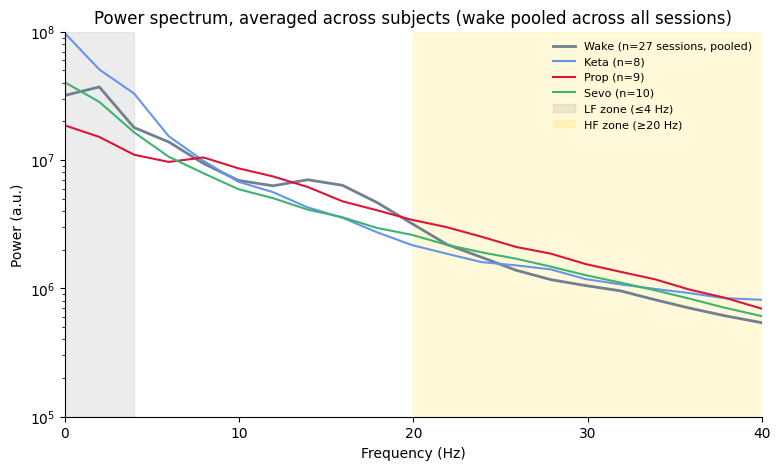

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))

# pool every wake recording across all three anesthesia sessions into one spectrum
all_wake_powers = []
for anes in ANES_TYPES:
    subjects_here = [s for s, avail in subject_to_anes.items() if anes in avail]
    for subj in subjects_here:
        wake, _ = dat.load_raw_pair(DATA_ROOT, subj, anes)
        freqs, wp = power_spectrum(wake['eeg'], wake['time_ms'])
        all_wake_powers.append(wp)

ax.plot(freqs, np.mean(all_wake_powers, axis=0), color=plotting.ANES_COLORS['wake'],
        lw=2, label=f'Wake (n={len(all_wake_powers)} sessions, pooled)')

for anes in ANES_TYPES:
    subjects_here = [s for s, avail in subject_to_anes.items() if anes in avail]
    anes_powers = []
    for subj in subjects_here:
        _, anes_rec = dat.load_raw_pair(DATA_ROOT, subj, anes)
        freqs, ap = power_spectrum(anes_rec['eeg'], anes_rec['time_ms'])
        anes_powers.append(ap)
    ax.plot(freqs, np.mean(anes_powers, axis=0), color=plotting.ANES_COLORS[anes],
            label=f'{anes.capitalize()} (n={len(subjects_here)})')

ax.axvspan(0, 4, color='gray', alpha=0.15, label='LF zone (≤4 Hz)')
ax.axvspan(20, freqs.max(), color='gold', alpha=0.15, label='HF zone (≥20 Hz)')
ax.set_yscale('log')
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Power (a.u.)')
ax.set_title('Power spectrum, averaged across subjects (wake pooled across all sessions)')
ax.legend(frameon=False, fontsize=8)
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 40), ylim=(1e5, 1e8), yticks=np.logspace(5, 8, 4))
plt.show()

In general we see that the power spectrum always lowers for higher frequencies. And that there is no super clear distinction between different conditions.

### HF/LF power ratio

The above plots have already seperated the frequency in different bins: all frequencies below 4 Hz into the LF zone and all frequencies above 25 Hz in the HF zone. Now we can boil this down to one ratio per channel per trial. Namely, we combine the weigth of all the frequencies below 4 Hz into the LF bin and all frequencies above 25 Hz into the HF bin. This is easier to interpret.

A priori (see theory above) we expect the values of this ratio to be: keta > wake > prop $\approx$ sevo

The plots below consist of violin plots, where the 25% percentile, mean and 75% percentile are indicated by horizontal lines.

In [16]:
def hf_lf_ratio(eeg, time_ms, window=(0, 500), lf_cutoff=4, hf_cutoff=25):
    """Per-channel, per-trial HF/LF power ratio. Returns array (channels, trials)."""
    mask = (time_ms >= window[0]) & (time_ms <= window[1])
    dt_s = np.mean(np.diff(time_ms[mask])) / 1000.0
    freqs = np.fft.rfftfreq(mask.sum(), d=dt_s)
    lf_mask, hf_mask = freqs < lf_cutoff, freqs > hf_cutoff
    fft = np.fft.rfft(eeg[mask], axis=0)
    power = np.abs(fft) ** 2  # (freqs, channels, trials)
    lf_power = power[lf_mask].sum(axis=0)
    hf_power = power[hf_mask].sum(axis=0)
    return np.where(lf_power > 0, hf_power / lf_power, np.nan)


def set_log10_yticks(ax, vmin, vmax):
    lo, hi = int(np.floor(vmin)), int(np.ceil(vmax))
    ticks = np.arange(lo, hi + 1)
    ax.set_yticks(ticks)
    ax.set_yticklabels([f'$10^{{{t}}}$' for t in ticks])


def plot_hf_lf_violin(subject, anes_list):
    fig, axes = plt.subplots(1, len(anes_list), figsize=(6 * len(anes_list), 4.5), squeeze=False)
    for ax, anes in zip(axes[0], anes_list):
        wake, anes_rec = dat.load_raw_pair(DATA_ROOT, subject, anes)
        wake_ratio = hf_lf_ratio(wake['eeg'], wake['time_ms'])   # (channels, trials)
        anes_ratio = hf_lf_ratio(anes_rec['eeg'], anes_rec['time_ms'])
        n_ch = wake_ratio.shape[0]
        positions = np.arange(1, n_ch + 1)
        wake_log_list = [np.log10(row[row > 0]) for row in wake_ratio]
        anes_log_list = [np.log10(row[row > 0]) for row in anes_ratio]

        wake_color = plotting.ANES_COLORS['wake']
        anes_color = plotting.ANES_COLORS[anes]

        vp_wake = ax.violinplot(wake_log_list, positions=positions - 0.15, widths=0.25,
                                 showmeans=False, showmedians=False, showextrema=False,
                                 quantiles=[[0.25, 0.75]] * n_ch)
        vp_anes = ax.violinplot(anes_log_list, positions=positions + 0.15, widths=0.25,
                                 showmeans=False, showmedians=False, showextrema=False,
                                 quantiles=[[0.25, 0.75]] * n_ch)
        for body in vp_wake['bodies']:
            body.set_facecolor(wake_color); body.set_alpha(0.4); body.set_edgecolor('0.3')
        for body in vp_anes['bodies']:
            body.set_facecolor(anes_color); body.set_alpha(0.4); body.set_edgecolor('0.3')
        vp_wake['cquantiles'].set_color(wake_color)
        vp_anes['cquantiles'].set_color(anes_color)
        for body, log_ratio in zip(vp_wake['bodies'], wake_log_list):
            plotting.add_violin_mean_line(ax, body, np.nanmean(log_ratio), color=wake_color)
        for body, log_ratio in zip(vp_anes['bodies'], anes_log_list):
            plotting.add_violin_mean_line(ax, body, np.nanmean(log_ratio), color=anes_color)

        ax.set_xticks(positions)
        ax.set_xlabel('Channel')
        ax.set_ylabel('HF/LF ratio')
        pooled_log = np.concatenate(wake_log_list + anes_log_list)
        set_log10_yticks(ax, pooled_log.min(), pooled_log.max())
        ax.set_title(f'{subject} — {anes.capitalize()}')
        legend_patches = [plt.Rectangle((0, 0), 1, 1, facecolor=wake_color, alpha=0.4, label='Wake'),
                           plt.Rectangle((0, 0), 1, 1, facecolor=anes_color, alpha=0.4, label=anes.capitalize())]
        ax.legend(handles=legend_patches, frameon=False)
        plotting.modify_axis_spines(ax, which=['x', 'y'])
    fig.tight_layout()
    plt.show()


plotting.subject_explorer(plot_hf_lf_violin, subject_to_anes)

Dropdown(description='Subject:', index=2, options=('j07', 'j09', 'j12', 'j13', 'j14', 'j15', 'j18', 'j21', 'j2…

Output()

Now we pool all channels/trials/subjects to be able to plot wake vs. anesthesia.
Wake gets combined into a single box across all three anesthesia sessions, so this is one wake box plus one box per anesthesia type.

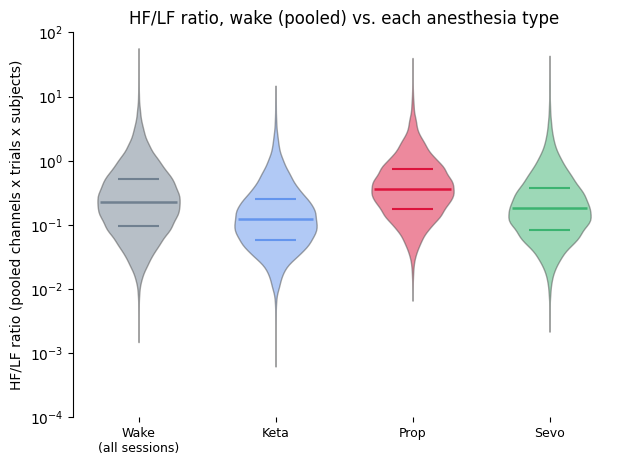

In [17]:
all_wake_vals = []
box_data, box_colors, labels = [], [], []
for anes in ANES_TYPES:
    subjects_here = [s for s, avail in subject_to_anes.items() if anes in avail]
    anes_vals = []
    for subj in subjects_here:
        wake, anes_rec = dat.load_raw_pair(DATA_ROOT, subj, anes)
        all_wake_vals.append(hf_lf_ratio(wake['eeg'], wake['time_ms']).ravel())
        anes_vals.append(hf_lf_ratio(anes_rec['eeg'], anes_rec['time_ms']).ravel())
    box_data.append(np.concatenate(anes_vals))
    box_colors.append(plotting.ANES_COLORS[anes])
    labels.append(anes.capitalize())
box_data = [np.concatenate(all_wake_vals)] + box_data
box_colors = [plotting.ANES_COLORS['wake']] + box_colors
labels = ['Wake\n(all sessions)'] + labels
box_positions = np.arange(1, len(box_data) + 1)
log_box_data = [np.log10(d[(~np.isnan(d)) & (d > 0)]) for d in box_data]

# cquantiles has 2 line segments per violin (Q1, Q3), in violin order, see set_color below
quantile_colors = [c for c in box_colors for _ in range(2)]

fig, ax = plt.subplots(figsize=(7, 5))
vp = ax.violinplot(log_box_data, positions=box_positions, widths=0.6, showmeans=False, showmedians=False,
                    showextrema=False, quantiles=[[0.25, 0.75]] * len(log_box_data))
for body, c in zip(vp['bodies'], box_colors):
    body.set_facecolor(c); body.set_alpha(0.5); body.set_edgecolor('0.3')
vp['cquantiles'].set_color(quantile_colors)
for body, log_data, c in zip(vp['bodies'], log_box_data, box_colors):
    plotting.add_violin_mean_line(ax, body, np.nanmean(log_data), color=c)
ax.set_xticks(box_positions)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel('HF/LF ratio (pooled channels x trials x subjects)')
pooled_log = np.concatenate(log_box_data)
set_log10_yticks(ax, pooled_log.min(), pooled_log.max())
ax.set_title('HF/LF ratio, wake (pooled) vs. each anesthesia type')
plotting.modify_axis_spines(ax, which=['y'])
plt.show()

We see that in general the ratio for prop and wake are the highest, while the ratio for keta and sevo the lowest. So the results don't match with the expectations ): .

## 5. Jansen-Rit model background + simulations

The Jansen-Rit model (in O. David's ERP formulation, used for DCM) is a neural mass model: instead of individual neurons, it tracks the average
membrane potential of three interacting populations (pyramidal cells, excitatory interneurons, and inhibitory interneurons) as a system of coupled
second-order ODEs, reduced here to 9 first-order state variables `x0`...`x8`. `x8` is the model's output: the simulated local field potential,
which is what gets compared to the recorded ERP.

Each population's output passes through a sigmoid nonlinearity (firing rate as a function of membrane potential) before feeding into the next population. The coupling strengths between populations are the **gain parameters** `g_1`...`g_4`. The remaining parameters (`delta`, `tau_e`/`tau_i`,
`h_e`/`h_i`, `u`) set the sigmoid's shape, the synaptic time constants, the synaptic gains, and a constant external input.

Scope for this project: We will try to link this Jansen-Rit model to the emperical data, via inference. This means that we will try to estimate the best set of parameters which correspond to the emperical datasets. And we will try to find relative differences in these fitted parameters between different conditions/subjects/anasthesia. 

For the main part of this project we only infer `g_1`...`g_4`, keeping everything else fixed at `jansen_rit.DEFAULT_PARAMS`. The reason for this is that, while allowing more parameters to vary will likely result in better fits/more correlations. This has a big danger of leaving us with parameter sets and relations between them which are non physical and really difficult to interpret. Therefore we keep it simple and interprebale, only varying the gain parameters, which are clearly linked to physical processes in the brain.

The default values of the parameters are given by:

In [18]:
jrm.PARAM_NAMES, jrm.DEFAULT_PARAMS

(['g_1', 'g_2', 'g_3', 'g_4', 'delta', 'tau_i', 'h_i', 'tau_e', 'h_e', 'u'],
 OrderedDict([('g_1', 0.42),
              ('g_2', 0.76),
              ('g_3', 0.15),
              ('g_4', 0.16),
              ('delta', 12.13),
              ('tau_i', 7.77),
              ('h_i', 27.88),
              ('tau_e', 5.77),
              ('h_e', 1.63),
              ('u', 3.94)]))

And simulations done with these parameters lead to:

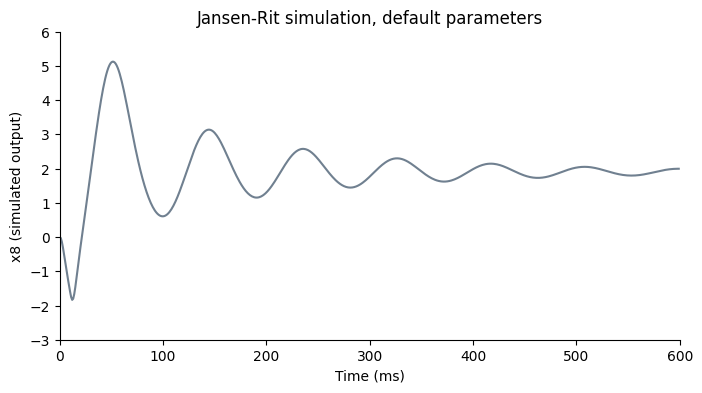

In [19]:
ts = np.arange(0.0, 600.0, 1.0)  # ms, RK4 dt_sim=1.0, the standard used everywhere from here on

trace_default = jrm.simulate_erp(ts)  # no overrides -> pure defaults, RK4 by default now

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ts, trace_default, color='slategray', lw=1.5)
ax.set_xlabel('Time (ms)')
ax.set_ylabel('x8 (simulated output)')
ax.set_title('Jansen-Rit simulation, default parameters')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(ts.min()), 600))
plt.show()

### Varying only the gain parameters `g_1..g_4`

This is the scope we for now infer, so it's worth seeing directly how much
the output shape changes when only these four parameters change.

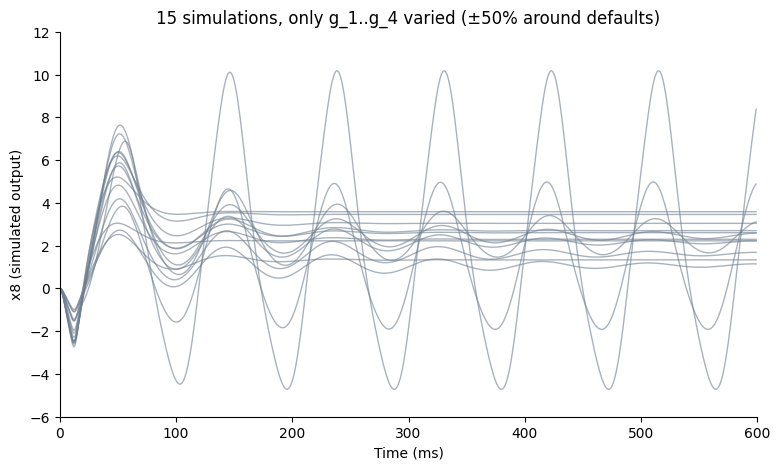

In [20]:
rng = np.random.default_rng(0)
n_sim = 15

fig, ax = plt.subplots(figsize=(9, 5))
for i in range(n_sim):
    g_overrides = {name: jrm.DEFAULT_PARAMS[name] * rng.uniform(0.5, 1.5) for name in jrm.FREE_PARAM_NAMES}
    trace = jrm.simulate_erp(ts, free_params=g_overrides)
    ax.plot(ts, trace, alpha=0.6, lw=1, color='slategray')

ax.set_xlabel('Time (ms)')
ax.set_ylabel('x8 (simulated output)')
ax.set_title(f'{n_sim} simulations, only g_1..g_4 varied (±50% around defaults)')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(ts.min()), 600))
plt.show()

### Varying all 10 parameters

We can also see what the rest of the parameter space does: letting `delta`, `tau_e`/`tau_i`,
`h_e`/`h_i` and `u` move too, on top of the gains.

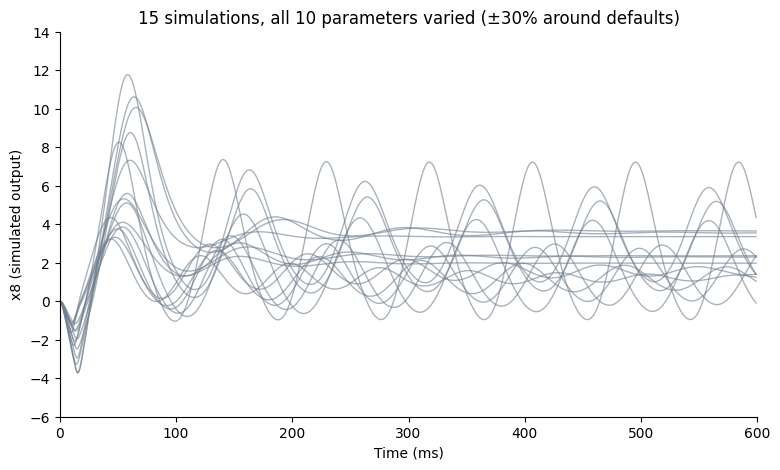

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
for i in range(n_sim):
    all_overrides = {name: val * rng.uniform(0.7, 1.3) for name, val in jrm.DEFAULT_PARAMS.items()}
    trace = jrm.simulate_erp(ts, free_params=all_overrides)
    ax.plot(ts, trace, alpha=0.6, lw=1, color='slategray')

ax.set_xlabel('Time (ms)')
ax.set_ylabel('x8 (simulated output)')
ax.set_title(f'{n_sim} simulations, all 10 parameters varied (±30% around defaults)')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(ts.min()), 600))
plt.show()

The full-parameter sweep produces a much wider range of shapes and amplitudes. That makes sense, since `tau_e`/`tau_i` and `h_e`/`h_i` directly
control the timescale and gain of the synaptic response, not just the connection strength. This is part of why the model is described as "highly
degenerate": very different parameter combinations can produce similar-looking traces, and restricting to `g_1..g_4` for now keeps the inference problem tractable.

### Different kinds of input, and noise

Everything above uses a constant external input `u` (`simulate_erp`). The model also has a second variant, `simulate_erp_temporal`, where the input is
a brief Gaussian pulse instead of a constant drive. That's a better match for what's actually happening experimentally (one electrical stimulus at *t = 0*, not a constant current), and it's the variant we use in the following notebooks.

`simulate_erp_temporal` can also add noise on top of the clean trace: a constant bias, white noise, and a damped (lowpass-filtered) version of that
white noise, controlled by `noise_params = (bias_amplitude, white_amplitude, noise_tau)`. A larger `noise_tau` means more filtering (smoother, more
correlated noise), a smaller one leaves it closer to raw white noise. 

First we plot the pulse input on its own, no noise, using different pulse variants.

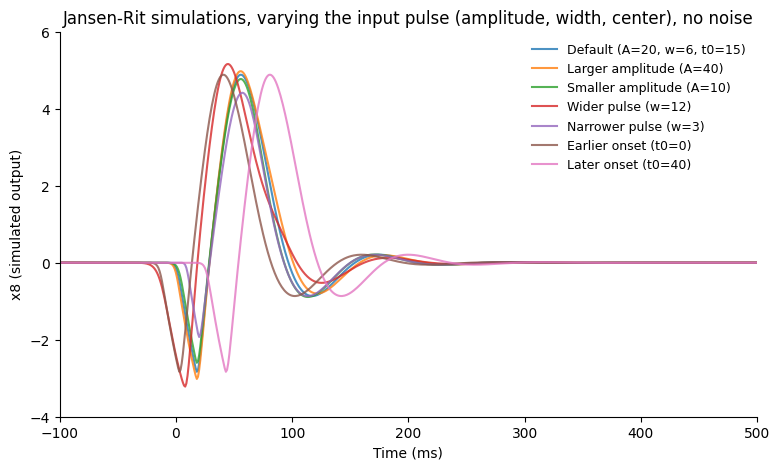

In [22]:
ts_temporal = np.arange(-100.0, 500.0, 1.0)  # ms, lined up with the empirical time axis used elsewhere
input_params = (20.0, 6.0, 15.0)  # amplitude, width (ms), center (ms), the default used elsewhere

pulse_variants = {
    'Default (A=20, w=6, t0=15)': (20.0, 6.0, 15.0),
    'Larger amplitude (A=40)': (40.0, 6.0, 15.0),
    'Smaller amplitude (A=10)': (10.0, 6.0, 15.0),
    'Wider pulse (w=12)': (20.0, 12.0, 15.0),
    'Narrower pulse (w=3)': (20.0, 3.0, 15.0),
    'Earlier onset (t0=0)': (20.0, 6.0, 0.0),    
    'Later onset (t0=40)': (20.0, 6.0, 40.0),
}

fig, ax = plt.subplots(figsize=(9, 5))
for label, pulse_params in pulse_variants.items():
    trace = jrm.simulate_erp_temporal(jnp.array(ts_temporal), pulse_params)
    ax.plot(ts_temporal, trace, lw=1.5, alpha=0.8, label=label)

ax.set_xlabel('Time (ms)')
ax.set_ylabel('x8 (simulated output)')
ax.set_title('Jansen-Rit simulations, varying the input pulse (amplitude, width, center), no noise')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(ts_temporal.min()), 500))
ax.legend(frameon=False, fontsize=9)
plt.show()

In the above plot it becomes clear that the amplitude of the input has almost no influence, the width of the pulse and the onset timing are the most important parameters. We stick for the rest of the project with the default parameters: A=20, w=6, t0=15.

Compared to the constant-input trace from before, the pulse input gives a response that actually starts flat, reacts to the stimulus, and settles back
down, closer in shape to a real evoked potential. Now the noise variants, a handful of random realizations per setting so the spread is visible.

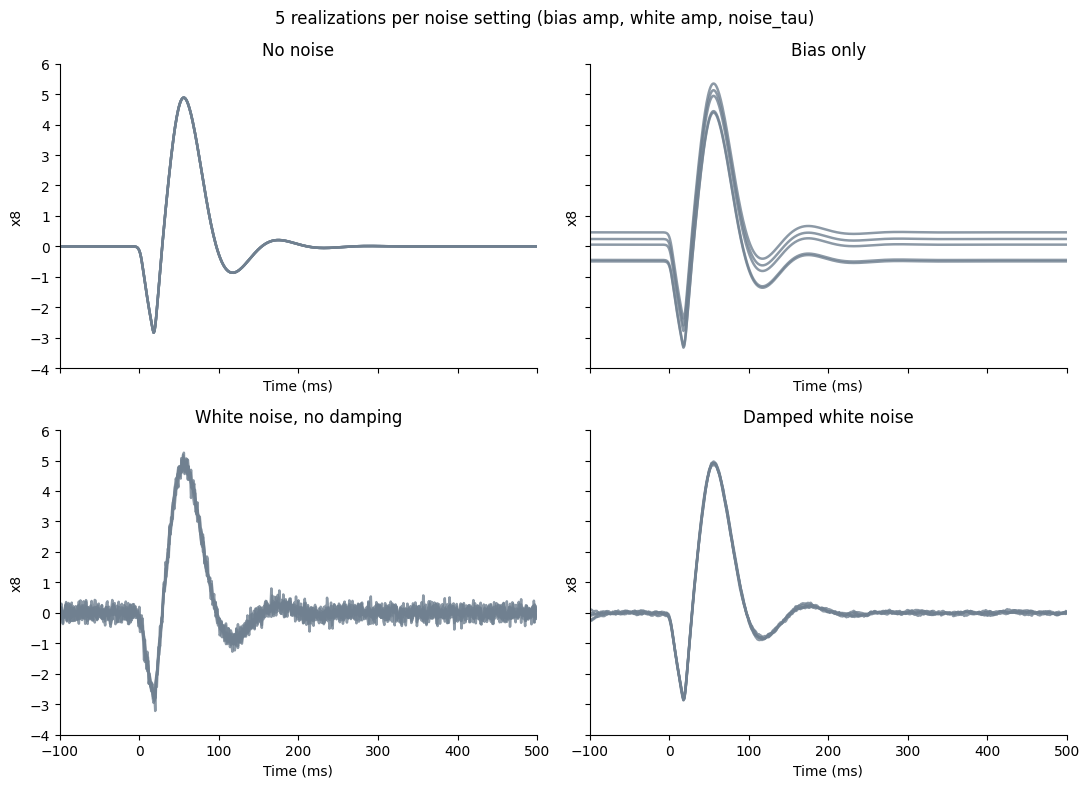

In [23]:
noise_variants = {
    'No noise': (0.0, 0.0, 1000),
    'Bias only': (0.5, 0.0, 1000),
    'White noise, no damping': (0.0, 0.5 / 3, 0),
    'Damped white noise': (0.0, 0.5 / 3, 10),
}

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
key = jax.random.PRNGKey(0)
n_realizations = 5

for ax, (label, noise_params_variant) in zip(axes.flat, noise_variants.items()):
    for i in range(n_realizations):
        key, subkey = jax.random.split(key)
        trace = jrm.simulate_erp_temporal(jnp.array(ts_temporal), input_params, key=subkey, noise_params=noise_params_variant)
        ax.plot(ts_temporal, trace, alpha=0.8, lw=1.8, color='slategray')
    ax.set_title(label)
    ax.set_xlabel('Time (ms)')
    ax.set_ylabel('x8')
    plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(np.min(ts_temporal)), 500))
fig.suptitle(f'{n_realizations} realizations per noise setting (bias amp, white amp, noise_tau)')
fig.tight_layout()
plt.show()

Bias just shifts the whole trace up or down by a random constant each run. Undamped-ish white noise (small `noise_tau`) adds visible jitter on top of
the clean shape. With `noise_tau` back up at 10 that same white noise gets smoothed into slow wandering instead of jitter, which is closer to what
real background EEG noise looks like.

Looking at this, we decide not to use any of this noise going forward. The rest of this notebook, and Notebooks 2 and 3, all run with the noise
amplitude at 0 from here on.

Now we can check wether a plausible simulated trace (pulse input, modest noise) land anywhere near real data, in shape and rough scale. This is just a sanity check of what we're actually aiming for before the MCMC/SBI notebooks try to match it properly :) .

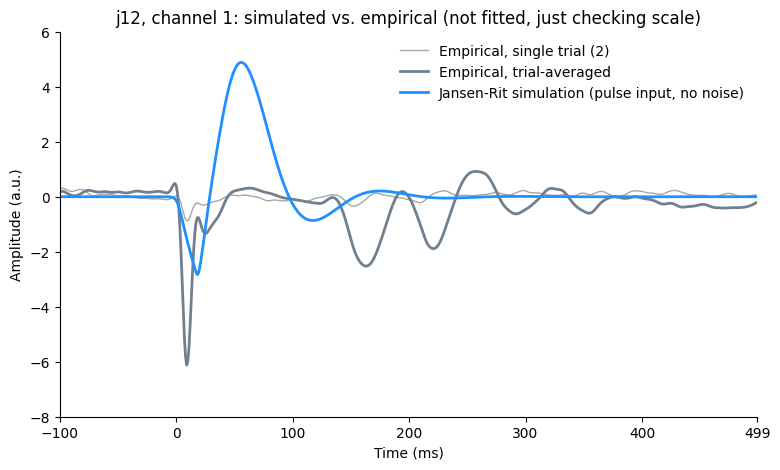

In [24]:
channel = 0
rng_trial = np.random.default_rng(1)

trial_wake = trial_datasets[example_anes].sel(subject=example_subject, condition='wake', region=channel)
random_trial_idx = int(rng_trial.integers(0, trial_wake.sizes['trial']))
single_trial_trace = trial_wake.isel(trial=random_trial_idx).to_numpy()
single_trial_time_ms = 1000 * trial_wake.coords['time'].values

avg_trace = erp_datasets[example_anes].sel(subject=example_subject, condition='wake', region=channel).to_numpy()
avg_time_ms = 1000 * erp_datasets[example_anes].coords['time'].values

key = jax.random.PRNGKey(3)
sim_trace = jrm.simulate_erp_temporal(jnp.array(ts_temporal), input_params, key=key, noise_params=(0.0, 0.0, 10))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(single_trial_time_ms, single_trial_trace, color='gray', lw=1, alpha=0.7, label=f'Empirical, single trial ({random_trial_idx})')
ax.plot(avg_time_ms, avg_trace, color=plotting.ANES_COLORS['wake'], lw=2, label='Empirical, trial-averaged')
ax.plot(ts_temporal, sim_trace, color='dodgerblue', lw=2, label='Jansen-Rit simulation (pulse input, no noise)')
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Amplitude (a.u.)')
ax.set_title(f'{example_subject}, channel {channel + 1}: simulated vs. empirical (not fitted, just checking scale)')
ax.legend(frameon=False)
_all_t = np.concatenate([single_trial_time_ms, avg_time_ms, np.asarray(ts_temporal)])
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(_all_t.min()), float(_all_t.max())))
plt.show()

The untuned simulation lands in a similar amplitude range with a broadly similar
post-stimulus bump. This looks good.

### Canonical Jansen-Rit vs. our own model

To be honest, we haven't used the canonical Jansen & Rit (1995) model for these simulations, but rather a reworked version of this model. Which is specifically designed for these kinds of inference codes of ERP signals.


It is worth seeing the two models side by side. But an importatant remark first: `jansen_rit.py`'s model has 9 states and a sigmoid that takes 2 state arguments (`sigmoid(x8, x4-x5, delta, alpha)`), while the textbook Jansen & Rit (1995) model is an 8 state system with a sigmoid on a single voltage. 

We compare our own model at its own g defaults (`g_1=0.42, g_2=0.76, g_3=0.15, g_4=0.16`, `jansen_rit.DEFAULT_PARAMS_TEMPORAL`) (which we will also use for the rest of this project), with the the canonical model using the standard parameters from Jansen and Rit (1995): `A=3.25 mV`, `B=22 mV`, `a=100 /s`, `b=50 /s`, `v0=6 mV`, `r=0.56 /mV`, `e0=2.5 /s`, and `C1=135` with the `1 : 0.8 : 0.25 : 0.25` ratio. 

This canonical model is driven with the same Gaussian pulse convention used everywhere else in this project, so the two models are being compared under the same kind of stimulus.

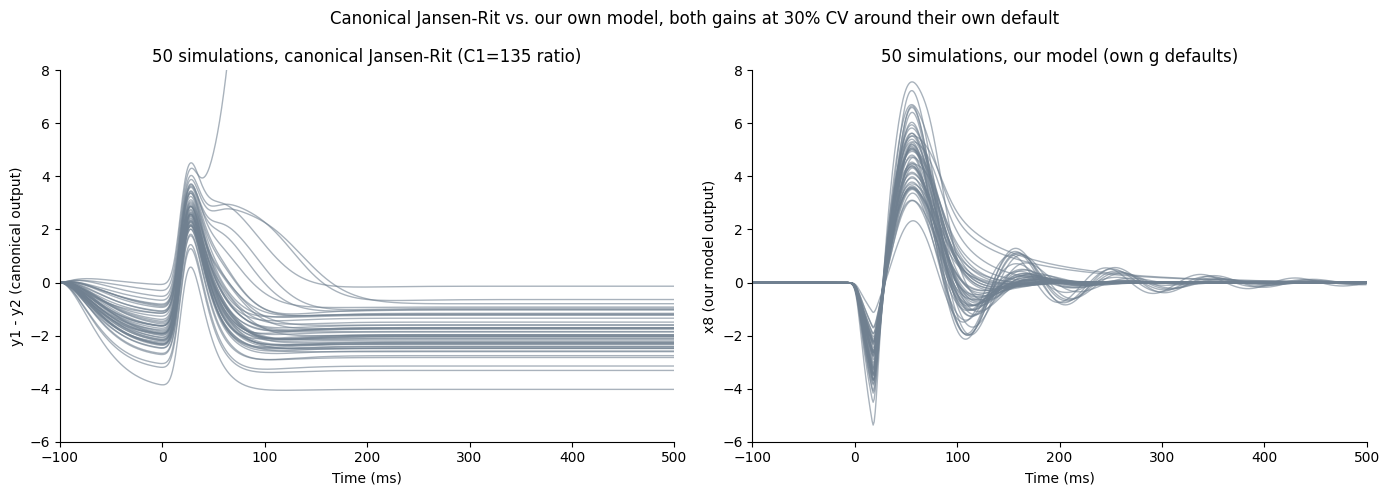

In [25]:
n_canon_demo = 50
noise_params_canon = (0.0, 0.0, 10)  # no noise, see the decision in the noise section above

canon_means = jnp.array([135.0, 0.8 * 135.0, 0.25 * 135.0, 0.25 * 135.0])
canon_stds = 0.3 * canon_means

original_means = jnp.array([jrm.DEFAULT_PARAMS_TEMPORAL[p] for p in jrm.FREE_PARAM_NAMES])
original_stds = 0.3 * original_means

canonical_pulse_params = (300.0, 6.0, 15.0)  # amplitude, width (ms), center (ms), own scale

rng_canon = np.random.default_rng(1)
canon_draws = rng_canon.normal(canon_means, canon_stds, size=(n_canon_demo, 4))
original_draws = rng_canon.normal(original_means, original_stds, size=(n_canon_demo, 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
key = jax.random.PRNGKey(2)

for i in range(n_canon_demo):
    key, subkey = jax.random.split(key)
    gains = tuple(canon_draws[i])
    trace = jrm.simulate_canonical_erp_temporal(ts_temporal, canonical_pulse_params, gains=gains,
                                                 key=subkey, noise_params=noise_params_canon)
    axes[0].plot(ts_temporal, trace, alpha=0.6, lw=1, color='slategray')

for i in range(n_canon_demo):
    key, subkey = jax.random.split(key)
    free_params = dict(zip(jrm.FREE_PARAM_NAMES, original_draws[i]))
    trace = jrm.simulate_erp_temporal(jnp.array(ts_temporal), input_params, free_params=free_params,
                                       key=subkey, noise_params=noise_params_canon)
    axes[1].plot(ts_temporal, trace, alpha=0.6, lw=1, color='slategray')

axes[0].set_title(f'{n_canon_demo} simulations, canonical Jansen-Rit (C1=135 ratio)')
axes[1].set_title(f'{n_canon_demo} simulations, our model (own g defaults)')
for ax in axes:
    ax.set_xlabel('Time (ms)')
    plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(ts_temporal.min()), 500), ylim=(-6, 8),
                                 yticks=np.arange(-6, 9, 2))
axes[0].set_ylabel('y1 - y2 (canonical output)')
axes[1].set_ylabel('x8 (our model output)')
fig.suptitle('Canonical Jansen-Rit vs. our own model, both gains at 30% CV around their own default')
fig.tight_layout()
plt.show()

Both panels mostly show a plausible rise-and-decay evoked response, and land in a broadly comparable amplitude range. 

But there is also a big difference: the canonical model does not settle back to zero before or after the pulse, it has a nonzero resting equilibrium. Our own model's near-zero pre/post-stimulus baseline is actually a convenient property for comparing against real ERPs, which get baseline corrected to sit around zero.

In the end it looks like a good decision to stay with our own model rather than switch.

### Choosing a prior: normal vs. log-uniform

Notebooks 2 and 3 both need a prior distribution to sample `g_1..g_4` from during inference. Now we will search for the best set of priors, which we will use for the rest of the project.

There are two different options: normal or log-uniform priors: 

1)  Log-uniform (uniform density on `log10(g)`): `g` is a gain/coupling strength, so it has to stay positive, and there is no strong reason a priori to expect it within one order of magnitude of the DCM defaults.

This prior gave the following problem: Long lasting oscillations show up specifically when the excitatory gains (`g_1`, `g_2`) land relatively large while the inhibitory gains (`g_3`, `g_4`) land relativaly small at the same time: weak damping relative to a strong excitatory drive pushes the
model past its stable fixed point into a limit cycle. This prior allows for this (as it has such a wide range).

2) Independent normal priors: mean at each parameter's DCM default, std at 30% of that mean, this way the priors are small enough to make sure that the ratio of `g_1` and `g_2` (excitation) with `g_3`, `g_4` (inhibition) doesn't become too large. This eliminates most bad simulations without needing to explicitly model the excitation/inhibition ratio.

Below, `n_prior_demo` simulations drawn from each prior, same pulse input and noise settings as the noise section above, side by side.

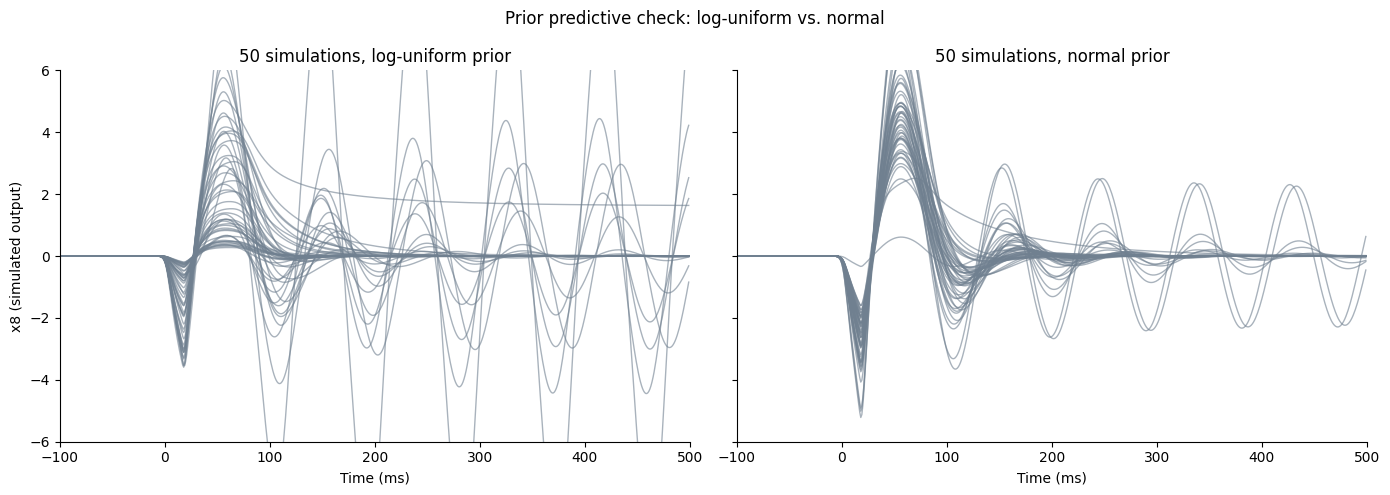

In [26]:
def sample_loguniform(rng, low, high, size):
    """Draw from a log-uniform distribution: uniform in log10(x), then exponentiate."""
    return np.exp(rng.uniform(np.log(low), np.log(high), size=size))

loguniform_bounds = {
    'g_1': (5e-2, 1e0),
    'g_2': (5e-2, 1e0),
    'g_3': (1e-2, 5e-1),
    'g_4': (1e-2, 5e-1),
}

prior_cv = 0.3  # normal prior's coefficient of variation, same for every g
normal_specs = {name: (jrm.DEFAULT_PARAMS_TEMPORAL[name], prior_cv * jrm.DEFAULT_PARAMS_TEMPORAL[name])
                for name in jrm.FREE_PARAM_NAMES}

n_prior_demo = 50
rng_prior = np.random.default_rng(0)

loguniform_theta = {name: sample_loguniform(rng_prior, *loguniform_bounds[name], n_prior_demo)
                     for name in jrm.FREE_PARAM_NAMES}
normal_theta = {name: rng_prior.normal(normal_specs[name][0], normal_specs[name][1], n_prior_demo)
                for name in jrm.FREE_PARAM_NAMES}

noise_params_demo = (0.0, 0.0, 10)  # no noise, see the decision in the noise section above

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
key = jax.random.PRNGKey(1)

for i in range(n_prior_demo):
    key, subkey = jax.random.split(key)
    free_params = {name: loguniform_theta[name][i] for name in jrm.FREE_PARAM_NAMES}
    trace = jrm.simulate_erp_temporal(jnp.array(ts_temporal), input_params, free_params=free_params,
                                       key=subkey, noise_params=noise_params_demo)
    axes[0].plot(ts_temporal, trace, alpha=0.6, lw=1, color='slategray')

for i in range(n_prior_demo):
    key, subkey = jax.random.split(key)
    free_params = {name: normal_theta[name][i] for name in jrm.FREE_PARAM_NAMES}
    trace = jrm.simulate_erp_temporal(jnp.array(ts_temporal), input_params, free_params=free_params,
                                       key=subkey, noise_params=noise_params_demo)
    axes[1].plot(ts_temporal, trace, alpha=0.6, lw=1, color='slategray')

axes[0].set_title(f'{n_prior_demo} simulations, log-uniform prior')
axes[1].set_title(f'{n_prior_demo} simulations, normal prior')
for ax in axes:
    ax.set_xlabel('Time (ms)')
    plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(ts_temporal.min()), 500), ylim=(-6, 6))
axes[0].set_ylabel('x8 (simulated output)')
fig.suptitle('Prior predictive check: log-uniform vs. normal')
fig.tight_layout()
plt.show()

In the end we see that the normal prior gives bettter results than the log-uniform prior, which results in more unstable oscillating simulations.

From now on we use the normal prior with std at 30% of the mean of the g-parameter.

We can already see a possible problem: namely that all simulations show the same (damped) harmonisc oscillator structure, while this is not the case for the emperical data.

### Errors and integrators

Above we already used RK4 at `dt_sim=1.0` ms for every simulation, as opposed to using Euler with a smaller time step. 

Here's why: we check how much `dt_sim` and the integrator (Euler vs. RK4) actually cost in accuracy and time, and whether `dt_sim=1.0` really holds up even for the tightest fits in Notebook 2.

In [27]:
n_err_draws = 50
rng_err = np.random.default_rng(0)
g_draws_err = {name: rng_err.normal(mean, std, n_err_draws) for name, (mean, std) in normal_specs.items()}

params_batch_err = np.tile(np.array([jrm.DEFAULT_PARAMS_TEMPORAL[p] for p in jrm.PARAM_NAMES_TEMPORAL]), (n_err_draws, 1))
for j, name in enumerate(jrm.FREE_PARAM_NAMES):
    params_batch_err[:, j] = g_draws_err[name]
params_batch_err = jnp.asarray(params_batch_err)

# a separate, bigger batch just for timing
n_time_draws = 1500
rng_time = np.random.default_rng(1)
params_batch_time = np.tile(np.array([jrm.DEFAULT_PARAMS_TEMPORAL[p] for p in jrm.PARAM_NAMES_TEMPORAL]), (n_time_draws, 1))
for j, name in enumerate(jrm.FREE_PARAM_NAMES):
    mean, std = normal_specs[name]
    params_batch_time[:, j] = rng_time.normal(mean, std, n_time_draws)
params_batch_time = jnp.asarray(params_batch_time)

burn_in_ms = 10.0
dt_data = 1.0  # ms, the empirical grid's native spacing after preprocessing (see step 3 above)
n_native = 501  # native 1 ms grid points we want, covers 0 to 500 ms


def build_ts_sim(dt_sim):
    """Same grid construction as mcmc.make_data_dict, so this matches Notebook 2's alignment behaviour exactly."""
    sim_factor = int(round(dt_data / dt_sim))
    n_burn = int(round(burn_in_ms / dt_sim))
    n_sim = n_burn + (n_native - 1) * sim_factor + 1
    ts_sim = -burn_in_ms + dt_sim * jnp.arange(n_sim)
    return ts_sim, n_burn, sim_factor


def simulate_aligned(dt_sim, integrator, batch=None):
    """Simulate every draw in batch at once, then slice down to the native 1 ms grid the same way the fit pipeline does."""
    batch = params_batch_err if batch is None else batch
    ts_sim, n_burn, sim_factor = build_ts_sim(dt_sim)
    integrate = jrm.odeint_rk4 if integrator == 'rk4' else jrm.odeint_euler
    x0 = jnp.zeros(jrm.N_STATES)

    def one(params_vec):
        xs = integrate(jrm.vector_field_temporal, x0, ts_sim, jrm.ALPHA_DEFAULT, params_vec, input_params)
        return xs[:, 8]

    traces = jax.vmap(one)(batch)
    return traces[:, n_burn:][:, ::sim_factor]


# reference: RK4 at dt=0.005 ms, this divides 1 ms exactly so the native grid points are exact
# hits on the fine grid, no interpolation needed to compare
ts_ref, n_burn_ref, sim_factor_ref = build_ts_sim(0.005)


def ref_one(params_vec):
    xs = jrm.odeint_rk4(jrm.vector_field_temporal, jnp.zeros(jrm.N_STATES), ts_ref, jrm.ALPHA_DEFAULT, params_vec, input_params)
    return xs[:, 8]


ref_traces = jax.vmap(ref_one)(params_batch_err)
ref_native = np.asarray(ref_traces[:, n_burn_ref:][:, ::sim_factor_ref])
print(f'Reference: RK4, dt=0.005 ms, {len(ts_ref)} points per simulation, {n_err_draws} draws from the g-priors')

Reference: RK4, dt=0.005 ms, 102001 points per simulation, 50 draws from the g-priors


In [28]:
dt_dividers = [0.1, 0.2, 0.25, 0.5, 1.0]      # evenly divide dt_data = 1.0 ms
dt_nondividers = [0.15, 0.3, 0.4, 0.7]   # don't, sim_factor has to round


def time_call(dt_sim, integrator, reps=3):
    """Best-of-reps wall time, batched over n_time_draws, to keep dispatch overhead from swamping the trend."""
    simulate_aligned(dt_sim, integrator, params_batch_time).block_until_ready()  # warmup, triggers jit compile
    best = min(_time_one_call(dt_sim, integrator) for _ in range(reps))
    return best


def _time_one_call(dt_sim, integrator):
    t0 = time.time()
    simulate_aligned(dt_sim, integrator, params_batch_time).block_until_ready()
    return time.time() - t0


sweep_rows = []
for integrator in ['euler', 'rk4']:
    for dt_sim in sorted(dt_dividers + dt_nondividers):
        aligned = dt_sim in dt_dividers
        out = np.asarray(simulate_aligned(dt_sim, integrator))
        err = out - ref_native
        elapsed = time_call(dt_sim, integrator)
        sweep_rows.append(dict(
            dt_sim=dt_sim, integrator=integrator, aligned=aligned,
            rms_100=float(np.sqrt(np.mean(err[:, :101] ** 2))),
            rms_500=float(np.sqrt(np.mean(err[:, :501] ** 2))),
            max_100=float(np.max(np.abs(err[:, :101]))),
            time_s=elapsed,
        ))

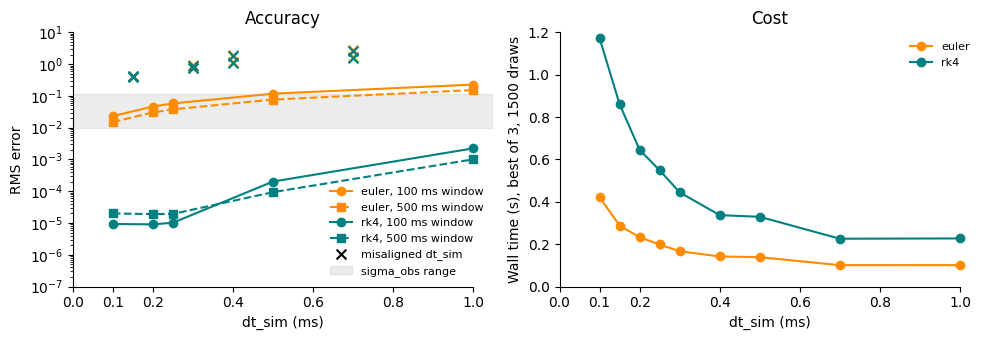

In [29]:
line_style = {'euler': dict(color='darkorange'), 'rk4': dict(color='teal')}
window_style = {'rms_100': dict(ls='-', marker='o'), 'rms_500': dict(ls='--', marker='s')}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

for integrator in ['euler', 'rk4']:
    for key in ['rms_100', 'rms_500']:
        aligned_rows = sorted([r for r in sweep_rows if r['integrator'] == integrator and r['aligned']], key=lambda r: r['dt_sim'])
        axes[0].plot([r['dt_sim'] for r in aligned_rows], [r[key] for r in aligned_rows],
                     label=f"{integrator}, {key[4:]} ms window", **line_style[integrator], **window_style[key])
        misaligned_rows = [r for r in sweep_rows if r['integrator'] == integrator and not r['aligned']]
        axes[0].scatter([r['dt_sim'] for r in misaligned_rows], [r[key] for r in misaligned_rows],
                         marker='x', s=50, color=line_style[integrator]['color'])

axes[0].scatter([], [], marker='x', s=50, color='black', label='misaligned dt_sim')
axes[0].axhspan(0.010, 0.112, color='gray', alpha=0.15, label='sigma_obs range')
axes[0].set_yscale('log')
axes[0].set_xlabel('dt_sim (ms)')
axes[0].set_ylabel('RMS error')
axes[0].set_title('Accuracy')
axes[0].set_ylim(1e-7, 1e1)
plotting.modify_axis_spines(axes[0], which=['x'], xlim=(0, 1.05), xticks=[0, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0])
axes[0].spines['left'].set_visible(True)
plotting.dedupe_legend(axes[0], frameon=False, fontsize=8, loc='lower right')

for integrator in ['euler', 'rk4']:
    rows = sorted([r for r in sweep_rows if r['integrator'] == integrator], key=lambda r: r['dt_sim'])
    axes[1].plot([r['dt_sim'] for r in rows], [r['time_s'] for r in rows], marker='o', label=integrator, **line_style[integrator])
axes[1].set_xlabel('dt_sim (ms)')
axes[1].set_ylabel(f'Wall time (s), best of 3, {n_time_draws} draws')
axes[1].set_title('Cost')
plotting.modify_axis_spines(axes[1], which=['x', 'y'], ylim=(0, 1.2), xlim=(0, 1.05), xticks=[0, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0])
plotting.dedupe_legend(axes[1], frameon=False, fontsize=8)

fig.tight_layout()
plt.show()

RK4 at `dt_sim=1.0` ms stays comfortably under `sigma_obs` even for the tightest fits in Notebook 2 (where the noise of the emperical data is as low as 0.01), so we use it everywhere now. 

We also see that non-dividing `dt_sim` values blow way past that error range regardless of integrator, so `dt_sim` has to evenly divide the data's 1 ms spacing. Otherwise we have to compare interpolated simulation points to real emperical data.

Simulation is the real time bottleneck in Notebook 2 (NUTS calls the simulator every step) and Notebook 3 spends real time on it too (performing all the initial simulations), so RK4 at `dt_sim=1.0` will be used everywhere.

## 6. PCIst
PCIst (Perturbational Complexity Index, State transitions) summarizes a multichannel evoked response as a single number capturing how spatiotemporally differentiated the response is. Given an ERP, PCIst is calculated as follows:

1. **Find candidate spatial patterns**: SVD the post stimulus response window across channels (baseline is zeroed out for this step). This gives up to `n_components` candidate spatial patterns, each one a fixed set of 16 channel weights, ranked by how much response variance they capture.
2. **Project each candidate over time**: for every candidate pattern, take the dot product of its channel weights with the ERP signal at every timepoint, baseline and response both. This turns each spatial pattern into a single trace over time.
3. **Variance gate**: keep only as many top patterns as needed for their combined variance in the response window to reach `max_var`% of the total.
4. **SNR gate**: for each candidate trace, compare its power during the response window to its power during baseline. Keep the component only if this ratio clears `min_snr`. Components that fail either gate are dropped from the final sum later, but their traces still get carried through the next steps so the computation has a fixed shape.
5. **Compare every timepoint to every other timepoint**: for each surviving trace, build a matrix (N timepoints x N timepoints) of how far apart the trace's value is between every pair of timepoints.
6. **Turn distance into a same or different call**: pick a candidate threshold. Pairs closer than it count as "same state," pairs further apart count as "different state."
7. **Count transitions**: read that same/different matrix one row at a time, each row being one fixed reference timepoint. Scanning along the row in time order, count every flip from same to different or back. Sum these flips separately for pairs that fall entirely within baseline and pairs that fall entirely within the response window (a pair with one foot in each window doesn't count).
8. **Normalize and set the threshold search range**: divide each of those two sums by the number of pairs in its own window, so baseline and response are compared as rates rather than raw counts. The range of thresholds to try comes from the data itself, from the typical (median) baseline distance up to the largest response distance, swept in 100 steps.
9. **Pick the best threshold per component**: out of that sweep, keep whichever threshold maximizes (response rate − `k` × baseline rate), with `k = 1.2` by default. Scale that best margin back up by the number of response timepoints to get the component's transition count.
10. **Sum across components**: components that failed the variance or SNR gate contribute zero, and any leftover negative margin is clipped to zero too. Adding up what remains gives the final PCIst value.

Intuition: a flat non response scores low, nothing changes state. A response that's identical on every channel also scores low after dimension reduction, since it collapses to one dominant component with not much complexity to count. A response that's both strong and differentiated across channels scores high.

This project uses the faster Jax JIT using `pcist.py` (Amirhossein Esmaeili's implementation) everywhere, not the external `PCIst` pip package.


Now we can test this PCIst on a preprocessed trial-averaged ERP, for wake data vs. every anesthesia data for an example subject.

Wake actually has up to 3 trial-averaged recordings for this subject, one per anesthesia session it went through. For the plot below, these get averaged into one global wake ERP, so there's a single wake trace to look at instead of three overlapping ones. Now we can plot these empirical average signals, with the baseline and response windows marked.

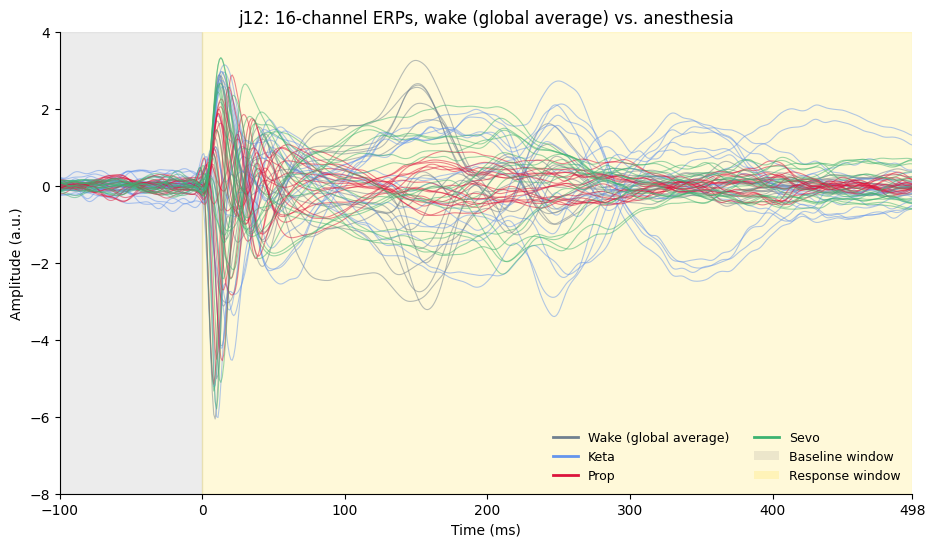

In [30]:
time_ms = 1000 * erp_datasets['keta'].coords['time'].values

# combine this subject's wake ERP across every anesthesia session into one global average
wake_das = [erp_datasets[anes].sel(subject=example_subject, condition='wake')
            for anes in subject_to_anes[example_subject]]
wake_erp_global = xr.concat(wake_das, dim='session').mean('session', skipna=True).dropna('region')

# per-anesthesia ERPs
anes_erps = {anes: erp_datasets[anes].sel(subject=example_subject, condition=anes).dropna('region')
             for anes in subject_to_anes[example_subject]}

fig, ax = plt.subplots(figsize=(11, 6))

for ch in range(wake_erp_global.sizes['region']):
    ax.plot(time_ms, wake_erp_global.isel(region=ch).to_numpy(),
            color=plotting.ANES_COLORS['wake'], alpha=0.5, lw=0.8)

for anes, anes_erp in anes_erps.items():
    for ch in range(anes_erp.sizes['region']):
        ax.plot(time_ms, anes_erp.isel(region=ch).to_numpy(),
                color=plotting.ANES_COLORS[anes], alpha=0.5, lw=0.8)

# baseline/response windows
ax.axvspan(time_ms.min(), 0, color='gray', alpha=0.15)
ax.axvspan(0, time_ms.max(), color='gold', alpha=0.15)


legend_handles = [plt.Line2D([0], [0], color=plotting.ANES_COLORS['wake'], lw=2, label='Wake (global average)')]
for anes in anes_erps:
    legend_handles.append(plt.Line2D([0], [0], color=plotting.ANES_COLORS[anes], lw=2, label=anes.capitalize()))
legend_handles.append(plt.Rectangle((0, 0), 1, 1, facecolor='gray', alpha=0.15, label='Baseline window'))
legend_handles.append(plt.Rectangle((0, 0), 1, 1, facecolor='gold', alpha=0.15, label='Response window'))
ax.legend(handles=legend_handles, frameon=False, ncol=2, fontsize=9)

ax.set_xlabel('Time (ms)')
ax.set_ylabel('Amplitude (a.u.)')
ax.set_title(f'{example_subject}: 16-channel ERPs, wake (global average) vs. anesthesia')
plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(float(time_ms.min()), float(time_ms.max())))
plt.show()

Now we can calculate the corresponding PCIst values. Unlike the plot above, wake PCIst here is computed separately for each anesthesia session rather than from one combined average, since PCIst is not just an amplitude summary the way the plot is, and computing it once per session lets us see directly how much it varies session to session for the same subject, shown as the error bar on the wake bar below.

Also I first tried to average over all wake ERP's and calculate from that one PCIst value, but I ran into problems regarding bad channels.

Computing PCIst:   0%|          | 0/3 [00:00<?, ?it/s]

keta: wake PCIst = 112.83, keta PCIst = 62.51
prop: wake PCIst = 88.79, prop PCIst = 72.77
sevo: wake PCIst = 76.31, sevo PCIst = 60.30


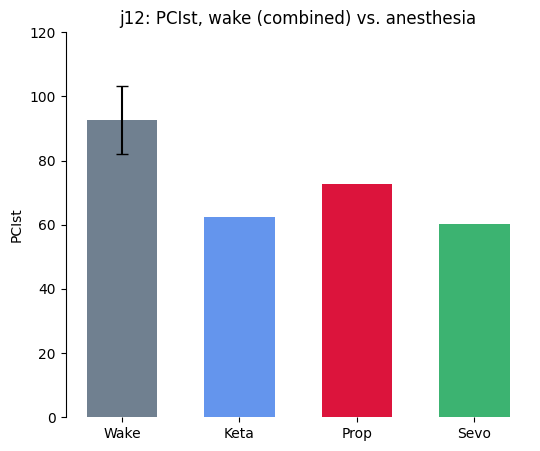

In [31]:
n_timepoints = erp_datasets['keta'].sizes['time']
baseline_samples = 100  # raw crop (tbeg=2450 at 500 Hz) starts exactly 100 ms before stimulus onset
pci_time_vec = np.linspace(-baseline_samples, n_timepoints - baseline_samples, n_timepoints)
pci_params = dict(baseline_window=(pci_time_vec.min(), 0), response_window=(0, pci_time_vec.max()),
                   k=1.2, min_snr=1.1, max_var=99, embed=False, n_steps=100)

# wake PCIst computed once per anesthesia session here (not from the combined average used
# for the plot above), so the wake bar below gets an error bar showing session-to-session
# spread. anes_erps is reused from the ERP plot cell above for the anesthesia side.
wake_pcis, anes_results = [], []
for anes in tqdm(subject_to_anes[example_subject], desc='Computing PCIst'):
    wake_erp = erp_datasets[anes].sel(subject=example_subject, condition='wake').dropna('region').T.to_numpy()
    anes_erp_np = anes_erps[anes].T.to_numpy()
    wake_pci = pcist.compute_pci_single(
        jnp.array(wake_erp), pci_time_vec, n_components=wake_erp.shape[0], **pci_params)
    anes_pci = pcist.compute_pci_single(
        jnp.array(anes_erp_np), pci_time_vec, n_components=anes_erp_np.shape[0], **pci_params)
    wake_pcis.append(float(wake_pci))
    anes_results.append((anes, float(anes_pci)))
    print(f'{anes}: wake PCIst = {wake_pci:.2f}, {anes} PCIst = {anes_pci:.2f}')

fig, ax = plt.subplots(figsize=(6, 5))
plotting.plot_condition_bars(
    ax, condition_labels=[r[0] for r in anes_results], condition_values=[r[1] for r in anes_results],
    condition_colors=[plotting.ANES_COLORS[r[0]] for r in anes_results], wake_values=wake_pcis,
    ylabel='PCIst')
ax.set_title(f'{example_subject}: PCIst, wake (combined) vs. anesthesia')
plt.show()

We see that the wake ERP data has a higher PCIst score than the anesthesia data. This is as expected!

### Looking under the hood

The bar chart above only shows the final number. Before trusting it, it's
worth checking what happened inside for one example signal: out of the 16
spatial components (one per channel, before SVD reduction), how many
actually explained enough variance and had a strong enough response/baseline
SNR to pass the gate from step 1 above and count toward the PCIst sum.
`pcist.reduce_dimensions` does exactly that step and returns, per component:
`var_exp` (percent of variance it explains), `snrs` (response power vs.
baseline power) and `component_mask` (whether it passed both gates).

In [32]:
example_anes_for_pci = subject_to_anes[example_subject][0]
example_erp = erp_datasets[example_anes_for_pci].sel(subject=example_subject, condition='wake').dropna('region').T.to_numpy()

signal_svd, var_exp, eigenvalues, snrs, component_mask = pcist.reduce_dimensions(
    jnp.array(example_erp), pci_time_vec, pci_params['response_window'], example_erp.shape[0],
    pci_params['max_var'], pci_params['min_snr'], pci_params['baseline_window'])

pci_value = pcist.compute_pci_single(jnp.array(example_erp), pci_time_vec, n_components=example_erp.shape[0], **pci_params)

print(f"PCIst: {float(pci_value):.2f}")
print(f"variance explained per component (%): {np.round(np.array(var_exp), 1)}")
print(f"SNR per component: {np.round(np.array(snrs), 2)}")
print(f"components kept (passed variance + SNR gate): {np.array(component_mask)}")

PCIst: 112.83
variance explained per component (%): [78.9  9.3  7.3  1.8  1.   0.6  0.5  0.4  0.1  0.1  0.   0.   0.   0.
  0.   0. ]
SNR per component: [10.93 10.26  2.24  8.05  2.58  2.58  2.78  2.6   3.28  1.09  1.12  1.17
  0.43  0.69  1.28  6.17]
components kept (passed variance + SNR gate): [ True  True  True  True  True  True  True False False False False False
 False False False False]


### Computing PCIst for every subject, and saving it to disk

The worked example above was just one subject. Now we do this for everyone and save it: one `compute_pci_single` call per subject per condition (per
trial too, for the trial-resolved version). The result gets saved to `data/processed/` so `03_sbi.ipynb` can load it directly (these values get
reused as the empirical PCIst features the SBI posterior gets conditioned on).

Important remark: now we calculate 3 different PCIst values from the 3 average wake ERPs (one wake per available anesthesia per subject).

In [33]:
assert trial_datasets['keta'].sizes['time'] == n_timepoints, (
    'trial-resolved and trial-averaged time axes are expected to match here, '
    'so pci_time_vec can be reused for both'
)

pci_dims_avg = ['subject', 'condition']

for anes in ANES_TYPES:
    da = erp_datasets[anes]
    pci_array = xr.DataArray(
        np.zeros((da.sizes['subject'], 2)), dims=pci_dims_avg,
        coords={'subject': da.subject, 'condition': ['wake', anes]})

    for subj in da.subject.to_numpy():
        wake_erp = da.sel(subject=subj, condition='wake').dropna('region').T.to_numpy()
        anes_erp = da.sel(subject=subj, condition=anes).dropna('region').T.to_numpy()

        wake_pci = pcist.compute_pci_single(jnp.array(wake_erp), pci_time_vec, n_components=wake_erp.shape[0], **pci_params)
        anes_pci = pcist.compute_pci_single(jnp.array(anes_erp), pci_time_vec, n_components=anes_erp.shape[0], **pci_params)

        pci_array.loc[dict(subject=subj)] = [float(wake_pci), float(anes_pci)]
        print(f'{anes} {subj}: wake = {float(wake_pci):.2f}, {anes} = {float(anes_pci):.2f}')

    pci_array.to_netcdf(os.path.join(PROCESSED_DIR, f'{anes}_pcist.nc'))

print('\ntrial-averaged PCIst saved to', PROCESSED_DIR)

keta j12: wake = 112.83, keta = 62.51
keta j13: wake = 90.06, keta = 64.04
keta j14: wake = 57.28, keta = 55.22
keta j15: wake = 64.60, keta = 60.02
keta j23: wake = 58.58, keta = 61.95
keta j24: wake = 60.00, keta = 54.01
keta j25: wake = 53.05, keta = 35.02
keta j26: wake = 62.90, keta = 60.09
prop j07: wake = 69.57, prop = 50.44
prop j12: wake = 88.79, prop = 72.77
prop j13: wake = 86.39, prop = 50.86
prop j14: wake = 59.40, prop = 37.69
prop j15: wake = 82.42, prop = 67.70
prop j23: wake = 48.45, prop = 71.02
prop j24: wake = 62.24, prop = 47.56
prop j25: wake = 67.03, prop = 28.82
prop j26: wake = 58.89, prop = 65.62
sevo j07: wake = 57.62, sevo = 57.97
sevo j09: wake = 72.85, sevo = 59.47
sevo j12: wake = 76.31, sevo = 60.30
sevo j13: wake = 94.12, sevo = 52.68
sevo j14: wake = 54.70, sevo = 37.55
sevo j18: wake = 67.02, sevo = 63.54
sevo j21: wake = 42.27, sevo = 46.59
sevo j23: wake = 46.71, sevo = 62.86
sevo j25: wake = 52.39, sevo = 34.67
sevo j26: wake = 64.76, sevo = 44.83


Now the trial resolved PCIst values, the same 5 random trials as for the preprocessing. Now we don't take the average over the wake ERPs, we just calculate 5, 10 or 15 different wake trial resolved PCIst values per subject.

In [34]:
pci_dims_trials = ['subject', 'condition', 'trial']

for anes in ANES_TYPES:
    da = trial_datasets[anes]
    n_trials_here = da.sizes['trial']
    pci_array = xr.DataArray(
        np.zeros((da.sizes['subject'], 2, n_trials_here)), dims=pci_dims_trials,
        coords={'subject': da.subject, 'condition': ['wake', anes], 'trial': da.trial})

    for subj in da.subject.to_numpy():
        for tr in range(n_trials_here):
            wake_erp = da.sel(subject=subj, condition='wake', trial=tr).dropna('region').T.to_numpy()
            anes_erp = da.sel(subject=subj, condition=anes, trial=tr).dropna('region').T.to_numpy()

            wake_pci = pcist.compute_pci_single(jnp.array(wake_erp), pci_time_vec, n_components=wake_erp.shape[0], **pci_params)
            anes_pci = pcist.compute_pci_single(jnp.array(anes_erp), pci_time_vec, n_components=anes_erp.shape[0], **pci_params)

            pci_array.loc[dict(subject=subj, trial=tr)] = [float(wake_pci), float(anes_pci)]

        print(f'{anes} {subj}: {n_trials_here} trials computed')

    pci_array.to_netcdf(os.path.join(PROCESSED_DIR, f'{anes}_pci_trials.nc'))

print('\ntrial-resolved PCIst saved to', PROCESSED_DIR)
sorted(os.listdir(PROCESSED_DIR))

keta j12: 5 trials computed
keta j13: 5 trials computed
keta j14: 5 trials computed
keta j15: 5 trials computed
keta j23: 5 trials computed
keta j24: 5 trials computed
keta j25: 5 trials computed
keta j26: 5 trials computed
prop j07: 5 trials computed
prop j12: 5 trials computed
prop j13: 5 trials computed
prop j14: 5 trials computed
prop j15: 5 trials computed
prop j23: 5 trials computed
prop j24: 5 trials computed
prop j25: 5 trials computed
prop j26: 5 trials computed
sevo j07: 5 trials computed
sevo j09: 5 trials computed
sevo j12: 5 trials computed
sevo j13: 5 trials computed
sevo j14: 5 trials computed
sevo j18: 5 trials computed
sevo j21: 5 trials computed
sevo j23: 5 trials computed
sevo j25: 5 trials computed
sevo j26: 5 trials computed

trial-resolved PCIst saved to data/processed


['keta_all_erps.nc',
 'keta_pci_trials.nc',
 'keta_pcist.nc',
 'keta_single_trials.nc',
 'keta_sliding_pci.nc',
 'keta_sliding_pci_avg.nc',
 'prop_all_erps.nc',
 'prop_pci_trials.nc',
 'prop_pcist.nc',
 'prop_single_trials.nc',
 'prop_sliding_pci.nc',
 'prop_sliding_pci_avg.nc',
 'sevo_all_erps.nc',
 'sevo_pci_trials.nc',
 'sevo_pcist.nc',
 'sevo_single_trials.nc',
 'sevo_sliding_pci.nc',
 'sevo_sliding_pci_avg.nc']

Reload from disk again, such that these values are available here for any further exploratory cells without needing to
recompute anything (the GPU vs CPU check right below recomputes PCIst on
purpose, since that's the whole point of the comparison).

In [35]:
pcist_datasets = {anes: xr.load_dataarray(os.path.join(PROCESSED_DIR, f'{anes}_pcist.nc')) for anes in ANES_TYPES}
pci_trial_datasets = {anes: xr.load_dataarray(os.path.join(PROCESSED_DIR, f'{anes}_pci_trials.nc')) for anes in ANES_TYPES}

pcist_datasets['keta']

<xarray.DataArray (subject: 8, condition: 2)> Size: 128B
array([[112.83421326,  62.51275635],
       [ 90.05693817,  64.04277039],
       [ 57.28109741,  55.21707153],
       [ 64.60328674,  60.01637268],
       [ 58.58481598,  61.94861984],
       [ 60.        ,  54.01204681],
       [ 53.05116272,  35.0199585 ],
       [ 62.90361404,  60.08796692]])
Coordinates:
  * subject    (subject) object 64B 'j12' 'j13' 'j14' ... 'j24' 'j25' 'j26'
  * condition  (condition) object 16B 'wake' 'keta'

### Sliding-window PCIst

Everywhere else in this section, PCIst gets computed on one fixed window covering the whole response. Here we instead slide a 100 ms window (50 ms
steps, 10 windows total) across the response and recompute PCIst per window, to see how it evolves instead of collapsing it to one number. This
is purely exploratory dataset characterization, these sliding-window values do not feed into the SBI or MCMC fits.

This runs on the raw, un-preprocessed recordings, not `trial_datasets` / `erp_datasets`. The baseline window used here reaches back to -400 ms,
further than the ~-100 ms onward that the preprocessed data got cropped to in section 2. So sliding-window PCIst keeps using the raw
recordings with their own wider crop, and everything else in this notebook (worked example above, `{anes}_pcist.nc` / `{anes}_pci_trials.nc` below)
keeps using the preprocessed data. Whether that choice actually matters for the PCIst value gets checked directly further down.

We compute this for both: 
- the trial average ERP, matching how   `preprocess_trial_averaged` builds its trial average
- the trial resolved ERP, `n_trials_sliding = n_trials` trials per subject that `preprocess_trial_resolved` already selected

In [36]:
n_trials_sliding = n_trials  # reuse the same trial count as the trial-resolved preprocessing

sliding_pci_datasets, sliding_pci_avg_datasets = {}, {}

for anes in ANES_TYPES:
    subjects_here = [s for s, avail in subject_to_anes.items() if anes in avail]
    print(f'{anes}: computing sliding-window PCIst for {len(subjects_here)} subjects '
          f'({n_trials_sliding} trials each, plus the trial-averaged signal)')

    rng_sliding = np.random.default_rng(random_state)

    per_subject_pci, per_subject_pci_avg, window_centers = {}, {}, None
    for subj in tqdm(subjects_here, desc=f'{anes} subjects'):
        wake, anes_rec = dat.load_raw_pair(DATA_ROOT, subj, anes)

        wake_sel = rng_sliding.choice(wake['eeg'].shape[-1], size=min(n_trials_sliding, wake['eeg'].shape[-1]), replace=False)
        anes_sel = rng_sliding.choice(anes_rec['eeg'].shape[-1], size=min(n_trials_sliding, anes_rec['eeg'].shape[-1]), replace=False)

        window_centers, wake_pci = pcist.sliding_pci(wake['eeg'][:, :, wake_sel], wake['time_ms'], show_progress=False)
        _, anes_pci = pcist.sliding_pci(anes_rec['eeg'][:, :, anes_sel], anes_rec['time_ms'], show_progress=False)
        per_subject_pci[subj] = (wake_pci, anes_pci)

        # trial-averaged signal: mean over *all* raw trials (not just the subsample
        # above), matching how preprocess_trial_averaged builds erp_datasets. Pass it
        # through sliding_pci as a single "trial" (trailing axis of size 1).
        wake_mean_eeg = wake['eeg'].mean(axis=-1, keepdims=True)
        anes_mean_eeg = anes_rec['eeg'].mean(axis=-1, keepdims=True)
        _, wake_pci_avg = pcist.sliding_pci(wake_mean_eeg, wake['time_ms'], show_progress=False)
        _, anes_pci_avg = pcist.sliding_pci(anes_mean_eeg, anes_rec['time_ms'], show_progress=False)
        per_subject_pci_avg[subj] = (wake_pci_avg[0], anes_pci_avg[0])

    max_trials = max(max(w.shape[0], a.shape[0]) for w, a in per_subject_pci.values())
    pci_grid = np.full((len(subjects_here), 2, max_trials, len(window_centers)), np.nan)
    avg_grid = np.zeros((len(subjects_here), 2, len(window_centers)))
    for s_idx, subj in enumerate(subjects_here):
        wake_pci, anes_pci = per_subject_pci[subj]
        pci_grid[s_idx, 0, :wake_pci.shape[0], :] = wake_pci
        pci_grid[s_idx, 1, :anes_pci.shape[0], :] = anes_pci
        wake_pci_avg, anes_pci_avg = per_subject_pci_avg[subj]
        avg_grid[s_idx, 0, :] = wake_pci_avg
        avg_grid[s_idx, 1, :] = anes_pci_avg

    sliding_da = xr.DataArray(
        pci_grid, dims=('subject', 'condition', 'trial', 'window'),
        coords={'subject': subjects_here, 'condition': ['wake', anes],
                'trial': np.arange(max_trials), 'window': window_centers})
    sliding_da.to_netcdf(os.path.join(PROCESSED_DIR, f'{anes}_sliding_pci.nc'))
    sliding_pci_datasets[anes] = sliding_da

    sliding_avg_da = xr.DataArray(
        avg_grid, dims=('subject', 'condition', 'window'),
        coords={'subject': subjects_here, 'condition': ['wake', anes], 'window': window_centers})
    sliding_avg_da.to_netcdf(os.path.join(PROCESSED_DIR, f'{anes}_sliding_pci_avg.nc'))
    sliding_pci_avg_datasets[anes] = sliding_avg_da

    print(f'{anes}: sliding-window PCIst done, saved to disk\n')

keta: computing sliding-window PCIst for 8 subjects (5 trials each, plus the trial-averaged signal)


keta subjects:   0%|          | 0/8 [00:00<?, ?it/s]

keta: sliding-window PCIst done, saved to disk

prop: computing sliding-window PCIst for 9 subjects (5 trials each, plus the trial-averaged signal)


prop subjects:   0%|          | 0/9 [00:00<?, ?it/s]

prop: sliding-window PCIst done, saved to disk

sevo: computing sliding-window PCIst for 10 subjects (5 trials each, plus the trial-averaged signal)


sevo subjects:   0%|          | 0/10 [00:00<?, ?it/s]

sevo: sliding-window PCIst done, saved to disk



Reload from disk before plotting.

In [1]:
sliding_pci_datasets = {anes: xr.load_dataarray(os.path.join(PROCESSED_DIR, f'{anes}_sliding_pci.nc')) for anes in ANES_TYPES}
sliding_pci_avg_datasets = {anes: xr.load_dataarray(os.path.join(PROCESSED_DIR, f'{anes}_sliding_pci_avg.nc')) for anes in ANES_TYPES}

NameError: name 'ANES_TYPES' is not defined

Now we can plot it, both the mean over single trials (with SEM band) and the
trial-averaged-signal value, per subject:

In [38]:
def plot_sliding_pci(subject, anes_list):
    fig, axes = plt.subplots(1, len(anes_list), figsize=(6 * len(anes_list), 4.5), squeeze=False)
    for ax, anes in zip(axes[0], anes_list):
        da = sliding_pci_datasets[anes]
        da_avg = sliding_pci_avg_datasets[anes]
        centers = da.coords['window'].values

        wake_trials = da.sel(subject=subject, condition='wake').dropna('trial').to_numpy()
        anes_trials = da.sel(subject=subject, condition=anes).dropna('trial').to_numpy()
        wake_mean, wake_sem = wake_trials.mean(0), wake_trials.std(0, ddof=1) / np.sqrt(wake_trials.shape[0])
        anes_mean, anes_sem = anes_trials.mean(0), anes_trials.std(0, ddof=1) / np.sqrt(anes_trials.shape[0])
        wake_avg = da_avg.sel(subject=subject, condition='wake').to_numpy()
        anes_avg = da_avg.sel(subject=subject, condition=anes).to_numpy()

        ax.plot(centers, wake_mean, marker='o', color=plotting.ANES_COLORS['wake'], label='Wake, mean over trials')
        ax.fill_between(centers, wake_mean - wake_sem, wake_mean + wake_sem, color=plotting.ANES_COLORS['wake'], alpha=0.2)
        ax.plot(centers, wake_avg, marker='o', linestyle='--', color=plotting.ANES_COLORS['wake'], alpha=0.5, label='Wake, trial-averaged signal')
        ax.plot(centers, anes_mean, marker='s', color=plotting.ANES_COLORS[anes], label=f'{anes.capitalize()}, mean over trials')
        ax.fill_between(centers, anes_mean - anes_sem, anes_mean + anes_sem, color=plotting.ANES_COLORS[anes], alpha=0.2)
        ax.plot(centers, anes_avg, marker='s', linestyle='--', color=plotting.ANES_COLORS[anes], alpha=0.5, label=f'{anes.capitalize()}, trial-averaged signal')

        ax.set_xlabel('Window center (ms)')
        ax.set_ylabel('PCIst')
        ax.set_title(f'{subject} \u2014 {anes.capitalize()}')
        ax.legend(frameon=False, fontsize=8)
        plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 500))
    fig.tight_layout()
    plt.show()

plotting.subject_explorer(plot_sliding_pci, subject_to_anes)

Dropdown(description='Subject:', index=2, options=('j07', 'j09', 'j12', 'j13', 'j14', 'j15', 'j18', 'j21', 'j2…

Output()

And averaged across subjects, per anesthesia type:

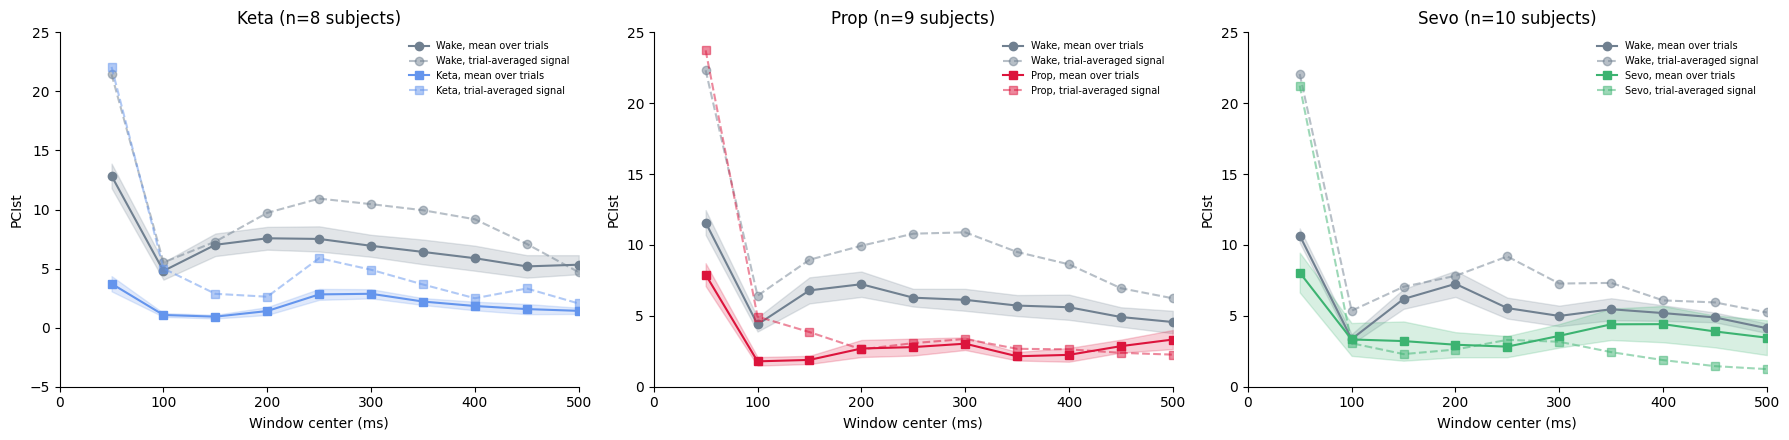

In [39]:
fig, axes = plt.subplots(1, len(ANES_TYPES), figsize=(6 * len(ANES_TYPES), 4.5))
for ax, anes in zip(axes, ANES_TYPES):
    da = sliding_pci_datasets[anes]
    da_avg = sliding_pci_avg_datasets[anes]
    centers = da.coords['window'].values
    n_subj = da.sizes['subject']

    wake_per_subject = da.sel(condition='wake').mean('trial', skipna=True)
    anes_per_subject = da.sel(condition=anes).mean('trial', skipna=True)
    wake_mean = wake_per_subject.mean('subject').to_numpy()
    wake_sem = wake_per_subject.std('subject', ddof=1).to_numpy() / np.sqrt(n_subj)
    anes_mean = anes_per_subject.mean('subject').to_numpy()
    anes_sem = anes_per_subject.std('subject', ddof=1).to_numpy() / np.sqrt(n_subj)

    wake_avg_mean = da_avg.sel(condition='wake').mean('subject').to_numpy()
    anes_avg_mean = da_avg.sel(condition=anes).mean('subject').to_numpy()

    ax.plot(centers, wake_mean, marker='o', color=plotting.ANES_COLORS['wake'], label='Wake, mean over trials')
    ax.fill_between(centers, wake_mean - wake_sem, wake_mean + wake_sem, color=plotting.ANES_COLORS['wake'], alpha=0.2)
    ax.plot(centers, wake_avg_mean, marker='o', linestyle='--', color=plotting.ANES_COLORS['wake'], alpha=0.5, label='Wake, trial-averaged signal')
    ax.plot(centers, anes_mean, marker='s', color=plotting.ANES_COLORS[anes], label=f'{anes.capitalize()}, mean over trials')
    ax.fill_between(centers, anes_mean - anes_sem, anes_mean + anes_sem, color=plotting.ANES_COLORS[anes], alpha=0.2)
    ax.plot(centers, anes_avg_mean, marker='s', linestyle='--', color=plotting.ANES_COLORS[anes], alpha=0.5, label=f'{anes.capitalize()}, trial-averaged signal')
    ax.set_title(f'{anes.capitalize()} (n={n_subj} subjects)')
    ax.set_xlabel('Window center (ms)')
    ax.set_ylabel('PCIst')
    ax.legend(frameon=False, fontsize=7)
    plotting.modify_axis_spines(ax, which=['x', 'y'], xlim=(0, 500))
fig.tight_layout()
plt.show()

Since PCIst is nonlinear: the mean of several single-trial PCIst values is not necessarily the same as the PCIst of the mean trace.

### Preprocessed vs. raw: does it change the PCIst value?

The sliding-window section above runs on raw data instead of the preprocessed data used everywhere else in this notebook, for the crop window reason explained above. Now we will check directly whether that actually matters: does normalizing + smoothing change the PCIst value compared to computing it straight on the raw, cropped recording? 


Remark: Raw data is at the native 500 Hz (2 ms/sample), the preprocessed data is at double that after `smooth_erp`'s 2x upsampling, so the PCIst time vector for the raw comparison needs a matching (half-sized) baseline sample count to cover the same real window.

In [40]:
def pci_from_time_by_channel(time_by_channel, time_vec, params):
    """signal in (time, channel) layout -> PCIst, transposes to the (channel, time) compute_pci_single expects."""
    arr = jnp.array(np.asarray(time_by_channel).T)
    return float(pcist.compute_pci_single(arr, time_vec, n_components=arr.shape[0], **params))


baseline_samples_raw = baseline_samples // 2  # raw data has half the sample rate of the smoothed/preprocessed data
n_timepoints_raw = tend - tbeg
pci_time_vec_raw = np.linspace(-baseline_samples_raw, n_timepoints_raw - baseline_samples_raw, n_timepoints_raw)
pci_params_raw = dict(baseline_window=(pci_time_vec_raw.min(), 0), response_window=(0, pci_time_vec_raw.max()),
                      k=1.2, min_snr=1.1, max_var=99, embed=False, n_steps=100)

other_subjects = [s for s in subject_to_anes if s != example_subject and example_anes in subject_to_anes[s]]
check_subjects = [example_subject] + other_subjects[:1]  # example subject plus one more, not the whole dataset

print(f'Trial-averaged PCIst, preprocessed vs. raw, {example_anes}\n')
for subj in check_subjects:
    wake_raw_full, anes_raw_full = dat.load_raw_pair(DATA_ROOT, subj, example_anes)
    wake_raw_mean = wake_raw_full['eeg'][tbeg:tend, :, :].mean(-1)  # (time, channel), no normalize, no smooth
    anes_raw_mean = anes_raw_full['eeg'][tbeg:tend, :, :].mean(-1)

    wake_pci_raw = pci_from_time_by_channel(wake_raw_mean, pci_time_vec_raw, pci_params_raw)
    anes_pci_raw = pci_from_time_by_channel(anes_raw_mean, pci_time_vec_raw, pci_params_raw)

    wake_pre = erp_datasets[example_anes].sel(subject=subj, condition='wake').dropna('region').to_numpy()
    anes_pre = erp_datasets[example_anes].sel(subject=subj, condition=example_anes).dropna('region').to_numpy()
    wake_pci_pre = pci_from_time_by_channel(wake_pre, pci_time_vec, pci_params)
    anes_pci_pre = pci_from_time_by_channel(anes_pre, pci_time_vec, pci_params)

    print(f'{subj}: wake raw={wake_pci_raw:.2f} preprocessed={wake_pci_pre:.2f}  |  '
          f'{example_anes} raw={anes_pci_raw:.2f} preprocessed={anes_pci_pre:.2f}')

Trial-averaged PCIst, preprocessed vs. raw, keta

j12: wake raw=108.93 preprocessed=112.83  |  keta raw=61.85 preprocessed=62.51
j13: wake raw=86.39 preprocessed=90.06  |  keta raw=60.95 preprocessed=64.04


We see that the preprocessing makes the PCIst value of the data always a bit higher. But as it makes every value higher, relatively speaking nothing big happens.

Same check but for individual trials instead of the trial average, this isolates the normalize+smooth transform on specific single trials of one
subject.

In [41]:
n_check_trials = 2
wake_raw_full, anes_raw_full = dat.load_raw_pair(DATA_ROOT, example_subject, example_anes)

print(f'Trial-resolved PCIst, preprocessed vs. raw, {example_subject}, {example_anes}\n')
for tr in range(n_check_trials):
    wake_trial_raw = wake_raw_full['eeg'][tbeg:tend, :, tr]
    anes_trial_raw = anes_raw_full['eeg'][tbeg:tend, :, tr]

    # same normalize + smooth steps preprocess_trial_resolved uses, applied to this one trial
    erp_max = max(np.abs(wake_trial_raw).max(), np.abs(anes_trial_raw).max())
    wake_trial_norm = wake_trial_raw / erp_max * amp_scaler
    anes_trial_norm = anes_trial_raw / erp_max * amp_scaler
    wake_trial_smooth, _ = dat.smooth_erp(wake_trial_norm, tbeg_sec, tend_sec, sfreq=500, axis=0)
    anes_trial_smooth, _ = dat.smooth_erp(anes_trial_norm, tbeg_sec, tend_sec, sfreq=500, axis=0)

    wake_pci_raw = pci_from_time_by_channel(wake_trial_raw, pci_time_vec_raw, pci_params_raw)
    anes_pci_raw = pci_from_time_by_channel(anes_trial_raw, pci_time_vec_raw, pci_params_raw)
    wake_pci_pre = pci_from_time_by_channel(wake_trial_smooth, pci_time_vec, pci_params)
    anes_pci_pre = pci_from_time_by_channel(anes_trial_smooth, pci_time_vec, pci_params)

    print(f'trial {tr}: wake raw={wake_pci_raw:.2f} preprocessed={wake_pci_pre:.2f}  |  '
          f'{example_anes} raw={anes_pci_raw:.2f} preprocessed={anes_pci_pre:.2f}')

Trial-resolved PCIst, preprocessed vs. raw, j12, keta

trial 0: wake raw=119.69 preprocessed=120.49  |  keta raw=20.78 preprocessed=20.26
trial 1: wake raw=79.13 preprocessed=79.19  |  keta raw=25.01 preprocessed=24.79


In the trial resolved case, the PCIst value changes less uniformaly.

As conclusion: preprocessing changes PCIst by only a few percent at most, well within noise relative to the wake/anesthesia effect size, so the choice to run PCIst on preprocessed data throughout the rest of the project doesn't introduce a meaningful problem.

### Checking `pcist.py` against the original CPU implementation

`pcist.py` is Amirhossein Esmaeili's JAX reimplementation of PCIst. The algorithm was originally published as a plain numpy package by Comolatti et al. (`PCIst`, the one the original notebooks imported as `pci_st`), that numpy version is the ground truth here, it's a direct implementation of the paper, with no JAX-specific tricks. Two things we will check: do the two implementations actually agree, and how much time does JAX/GPU actually buy us.

It's not on PyPI, install straight from the author's repo:

```
pip install git+https://github.com/renzocom/PCIst.git
```

In [42]:
try:
    from PCIst import pci_st
    have_pcist_reference = True
except ImportError:
    have_pcist_reference = False
    print("PCIst not installed, run: pip install git+https://github.com/renzocom/PCIst.git")

First a single signal, the same one used in the worked example above.

In [43]:
if have_pcist_reference:
    import time

    ref_params = dict(baseline_window=pci_params['baseline_window'], response_window=pci_params['response_window'],
                       k=pci_params['k'], min_snr=pci_params['min_snr'], max_var=pci_params['max_var'],
                       embed=pci_params['embed'], n_steps=pci_params['n_steps'])

    example_erp_np = np.array(example_erp)
    pci_time_vec_np = np.array(pci_time_vec)

    t0 = time.time()
    pci_cpu_ref = pci_st.calc_PCIst(example_erp_np, pci_time_vec_np, **ref_params)
    t_cpu = time.time() - t0

    # time the JAX version twice, the first call pays for JIT compilation
    t0 = time.time()
    pci_jax_cold = float(pcist.compute_pci_single(jnp.array(example_erp), pci_time_vec, n_components=example_erp.shape[0], **pci_params))
    t_jax_cold = time.time() - t0

    t0 = time.time()
    pci_jax_warm = float(pcist.compute_pci_single(jnp.array(example_erp), pci_time_vec, n_components=example_erp.shape[0], **pci_params))
    t_jax_warm = time.time() - t0

    rel_diff = 100 * abs(pci_jax_warm - pci_cpu_ref) / pci_cpu_ref

    print(f'numpy CPU reference : PCIst = {pci_cpu_ref:.3f}  ({t_cpu * 1000:.1f} ms)')
    print(f'our JAX version     : PCIst = {pci_jax_warm:.3f}  ({t_jax_cold * 1000:.1f} ms first call incl. JIT compile, {t_jax_warm * 1000:.1f} ms after)')
    print(f'relative difference : {rel_diff:.2f}%')

numpy CPU reference : PCIst = 113.602  (4349.5 ms)
our JAX version     : PCIst = 112.834  (305.9 ms first call incl. JIT compile, 54.8 ms after)
relative difference : 0.68%


A small difference here (typically around 0.7%) is found, the numpy version and the `pcist.py` version aren't doing bit-identical arithmetic. What matters is that they land on the same PCIst value within noise.

Now let's compare the time it takes in the case of batching: computing PCIst for many trials at once instead. So let's calculate the PCIst value of every wake trial available for this subject's anesthesia dataset.

40 trials, numpy CPU (python loop) : 38.61 s total
40 trials, JAX (batched, batch_size=10): 2.83 s total (incl. JIT compile)
max relative difference across trials: 9.2%


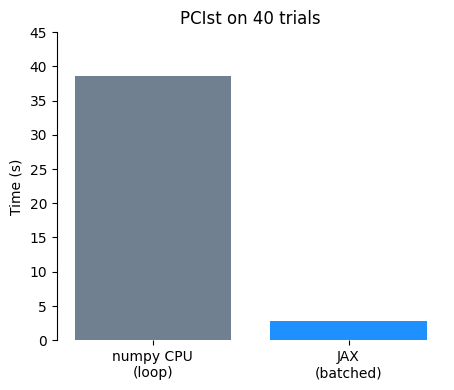

In [44]:
if have_pcist_reference:
    trial_da = trial_datasets[example_anes].sel(condition='wake').dropna('subject', how='all').dropna('region')
    trial_stacked = trial_da.stack(batch=('subject', 'trial')).transpose('batch', 'region', 'time')
    trial_batch_np = trial_stacked.to_numpy()
    trial_time_vec = 1000 * trial_stacked.coords['time'].values

    batch_baseline = (float(trial_time_vec.min()) + 5, 0)
    batch_response = (0, float(trial_time_vec.max()) - 5)
    batch_kwargs = dict(baseline_window=batch_baseline, response_window=batch_response,
                         k=1.2, min_snr=1.1, max_var=99, embed=False, n_steps=100)

    t0 = time.time()
    cpu_vals = np.array([pci_st.calc_PCIst(sig, trial_time_vec, **batch_kwargs) for sig in trial_batch_np])
    t_cpu_batch = time.time() - t0

    t0 = time.time()
    jax_vals = np.array(pcist.compute_pci_batch_chunked(
        jnp.array(trial_batch_np), jnp.array(trial_time_vec), batch_size=10,
        n_components=trial_batch_np.shape[1], **batch_kwargs))
    t_jax_batch = time.time() - t0

    n_trials_total = trial_batch_np.shape[0]
    max_rel_diff = 100 * np.max(np.abs(cpu_vals - jax_vals) / np.abs(cpu_vals))

    print(f'{n_trials_total} trials, numpy CPU (python loop) : {t_cpu_batch:.2f} s total')
    print(f'{n_trials_total} trials, JAX (batched, batch_size=10): {t_jax_batch:.2f} s total (incl. JIT compile)')
    print(f'max relative difference across trials: {max_rel_diff:.1f}%')

    fig, ax = plt.subplots(figsize=(5, 4))
    ax.bar(['numpy CPU\n(loop)', 'JAX\n(batched)'], [t_cpu_batch, t_jax_batch],
           color=[plotting.ANES_COLORS['wake'], 'dodgerblue'])
    ax.set_ylabel('Time (s)')
    ax.set_title(f'PCIst on {n_trials_total} trials')
    plotting.modify_axis_spines(ax, which=['y'])
    plt.show()

We see that the JAX version is indeed faster

## Wrap-up

What this notebook produced, that the other two will consume from
`data/processed/`:

- `{anes}_all_erps.nc`: trial-averaged ERPs, dims (subject, condition, time, region)
- `{anes}_single_trials.nc`: trial-resolved ERPs (n_trials per subject/condition), dims (subject, condition, trial, time, region)
- `{anes}_pcist.nc`: single (non-window) PCIst values on the trial-averaged data, dims (subject, condition)
- `{anes}_pci_trials.nc`: single (non-window) PCIst values on the trial-resolved data, dims (subject, condition, trial)

for each of `keta`, `prop`, `sevo`.

**Next up:**

- `02_mcmc.ipynb`: NumPyro/NUTS fit to a single subject/channel mean ERP, loads the datasets above directly.
- `03_sbi.ipynb`: full SBI workflow (P0→P4 pipelines), loads the datasets and the precomputed PCIst values above directly.

Both notebooks only alter the g parameters (`jansen_rit.FREE_PARAM_NAMES`) for the main part, but this can be extended without much work.

runtime: 258 sec